[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_BlackBoxBackdoorQUAP_Zhao2025.ipynb)

# QUAP, a black-box backdoor against quantum neural networks: Zhao et al. (2025) step by step

**Paper.** Jiayu Zhao, Lili Yan, Dong Tan, Yan Chang and Shibin Zhang, *A black-box backdoor attack against quantum neural networks*,
Quantum Science and Technology **10**, 035038 (2025), Chengdu University of Information Technology. DOI: <https://doi.org/10.1088/2058-9565/addf74>

**What this notebook does.** It re-implements the attack of the paper on MNIST digits 0-3, from scratch, in PyTorch (exact state-vector simulator) and PennyLane (the same circuits as `QNode`s):

1. an **attacker's QNN pool** of three differently structured quantum neural networks (QNN-A, QNN-B, QNN-C) trained on clean digits;
2. a **quantum-classical hybrid generative model**: a classical convolutional generator whose output is a *universal adversarial perturbation* (the "QUAP" trigger), trained to fool the whole pool with the targeted margin loss, the **non-target KL-divergence** term and the **min-max** re-weighting of the pool members (Algorithm 1);
3. **data poisoning**: 5 % of the training images get the trigger and the label "0"; three **unseen victim** QNN families (QNN1, QNN2, QNN3: other circuits, other depths) are trained on the poisoned set;
4. the paper's metrics, clean accuracy (CA) and attack success rate (ASR), for QUAP and for the two baselines (BadNets patch and Q-FGSM), and its experiments in miniature: Table 1, Table 2, temperature (Fig. 7), poisoning rate (Figs. 8-9, Table 3), and the two detection methods STRIP and spectral signatures (Figs. 10-11);
5. a classical baseline (random forest, RBF-SVM) on exactly the same 256 inputs, and an honest side-by-side comparison with the paper's numbers.

**How to run.** Open in Google Colab (button above), choose a **CPU** runtime and press *Runtime -> Run all*. `FAST_MODE = True` is a class demo that finishes in about ten minutes (shallow circuits, a few hundred images);
`False` is the longer run with the budgets documented in the configuration cell (about 80 minutes on one shared CPU core). **The outputs stored in this copy come from the full run (`FAST_MODE = False`).** Nothing needs a GPU, an IBM account or a Hugging Face token: MNIST is public.
(If you ever swap in a *gated* dataset, put your own token in Colab *Settings -> Secrets* as `HF_TOKEN`; the code below looks for it there and in the environment variable `HF_TOKEN`.)

**What you get at the end.** A pool of surrogate QNNs, a generated trigger, backdoored and clean victims, drawings of every executed circuit, figures re-drawn from the paper, a table that puts every number of the paper
next to the number measured here with a verdict ("reproduced", "not reached", "exceeded", "cannot be checked"), and exercises.

> **Ethics.** This is a security-research reproduction. It attacks only toy digit classifiers trained inside this notebook, to understand the threat and to test defences.

## The paper in one page

**Problem.** A *backdoor* is a hidden behaviour planted during training: the model is accurate on clean inputs but outputs an attacker-chosen class when a secret *trigger* is present. Earlier quantum backdoors need the circuit
(QTrojan, QDoor: white-box) or work only at high poisoning rates (Q-FGSM). Here the attacker only controls **the training data** (e.g. a public data repository) and does **not know the victim's circuit** (black box).

**Idea.** Use a *universal adversarial perturbation* (UAP) as the trigger. A UAP is one perturbation that pushes many images towards a chosen class; it already contains "target-class features", so a few poisoned samples are enough
for the victim to associate it with the target label. To make it transfer to unknown circuits, it is optimised against a **pool of QNNs with different structures**.

**Method (Section 4).**
* Generator `G` (classical deep-convolutional net, 3 blocks, kernel 4, stride 1 then 2, LeakyReLU 0.2): a fixed random vector `z` gives the perturbation `delta`, kept inside `||delta||_inf <= eps = 0.3`. Poisoned image: `x' = clip(x + delta)`.
* Loss on the pool (Eq. 4-6): targeted margin loss `L_t = max( max_{i != t} f_i - f_t , -k )`, `k = 10`, plus `lambda * L_nkl`, `lambda = 1`, where `L_nkl = sum_k KL( softmax(f_hat) || softmax(l_hat_k) )` compares the ensemble logits with the logits of the k-th model **without the target class** (temperature `T`).
* Min-max (Eq. 7-9): `min_delta max_w sum_k w_k L_all(l_k(x + delta)) - K ||w - 1/K||^2`, `w` on the simplex, gradient *ascent* on `w`, projected gradient *descent* on `delta` (here through the generator).
* Algorithm 1: stop when the fooling rate on the pool exceeds `T_fool = 0.9` or after `I` rounds; only samples not yet classified as the target contribute.
* Victims (Section 5.1): MNIST digits **0-3** (24 754 training and 4 157 test images), images pooled to **16x16**, **amplitude encoding**, QNN1 [Schuld et al.], QNN2 [Chen et al.], QNN3 [Manzano et al.] with 10, 30 and 50 layers; Adam, batch 64, learning rate 1e-3, 30 epochs;
  generator 50 rounds; poisoning rate **0.05**, target class 0. Pool members QNN-A/B/C: 10 qubits, amplitude encoding, 20 layers.
* Metrics (Section 3.3): **CA** (accuracy on clean test data) and **ASR** (share of triggered inputs classified as the target class).

**Claims we can test here.** Table 1: QUAP ASR > 98 % on three victims with CA about 92-93 % (clean model about 93 %), while Q-FGSM (ASR 13-17 %) and patch (ASR 7-9 %) fail at the same 5 % poisoning.
Table 2: depth and pool membership change the ASR only a little. Fig. 7: the ASR peaks at "T = 80". Table 3: ASR 51 / 83 / 92 / 97 % at poisoning rates 1 / 2 / 3 / 4 %, baselines stay below 9 %.
Figs. 10-11: spectral signatures and STRIP cannot detect the backdoor.

### What follows the paper and what had to be chosen

The paper publishes no code and its data are "available on request". The U-units of the pool (Fig. 4) and the victim circuits are given only as references and figures. Everything that is not in the text is a *choice*, marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | MNIST digits 0-3, all 24 754 / 4 157 images, resized to 16x16 | same data (public MNIST mirror), 16x16 by area (average) pooling, **random subsets with the natural class proportions**: 700 / 600 images (FAST) or 1 500 / 1 500 (full) because the circuit is simulated on a CPU (**CHOICE**) |
| Qubits and encoding | "10 qubits", amplitude encoding, `d = 2^n` | **8 qubits**: a 16x16 image has exactly 256 = 2^8 amplitudes, and 10 qubits would need 1 024 amplitudes (**deviation**, the text is inconsistent) |
| Readout and logits | not stated | Pauli-Z expectation of qubits 0-3 = 4 class logits, multiplied by 8 (**CHOICE**) |
| Pool members | QNN-A/B/C, Fig. 4 (not reproducible from the text), 20 layers | A: RX-RZ + CNOT ladder; B: RY-RZ-RY + CZ ring; C: RY + parametrised ZZ (Ising) ring; 20 layers (6 in FAST) (**CHOICE**) |
| Victims | QNN1 [42], QNN2 [43], QNN3 [44] with 10 / 30 / 50 layers | QNN1: general rotation + CNOT(q, q+r) with r changing per layer; QNN2: CNOT ring then RX-RY-RZ; QNN3: RY-RZ + CZ ladder (**CHOICE**: the exact wiring of the cited circuits); 10 / 30 / 50 layers in the full run, 4 / 6 / 8 in FAST |
| Weights initialisation, optimiser | Adam, lr 1e-3, 30 epochs on 24 754 images | Adam, **lr 0.05**, 8 (FAST) or 12 (full) epochs on a few hundred / thousand images: with a short CPU budget lr 1e-3 does not converge (**CHOICE**) |
| Attacker's surrogate data | not stated | the pool is trained on the clean training images (the attacker supplies the dataset) (**CHOICE**) |
| Trigger | `||delta||_inf <= 0.3`, pixels in [0, 1] | same; `delta = 0.3 tanh(G(z))`, `x' = clip(x + delta, 0, 1)` |
| Generator | 3 blocks, kernel 4, stride 1,2,2, LeakyReLU 0.2 | `ConvTranspose2d` 100 -> 128 -> 64 -> 1 (4x4 -> 8x8 -> 16x16), Adam lr 0.01 (**CHOICE**: size of `z`, channels, lr) |
| `T` ("80 degrees C"), `lambda`, `k`, fooling threshold | 80, 1, 10, 0.9 | `T` read as the softmax **temperature**; KL multiplied by `T^2` (distillation convention, **CHOICE**) so that `T = 80` is not inert; the rest as in the paper |
| Min-max step | `alpha` not given | `alpha = 0.1`, projection onto the simplex (**CHOICE**) |
| Poisoning | 5 % of the training set, non-0 samples relabelled 0 | same (rate counted on the whole training set) |
| Baseline "patch" | 3x3 square, bottom right | 3x3 white square (pixel value 1) |
| Baseline "Q-FGSM" | gradient trigger of Huang and Zhang, "other parameters as original" | **CHOICE**: universal one-step FGSM on one surrogate QNN with the same budget `eps = 0.3` (the original is not specified well enough to copy) |
| STRIP / spectral signatures | 100 test samples, 50 clean + 50 poisoned | same protocol on the QNN1 victim; representation = post-ansatz state (real and imaginary parts) (**CHOICE**) |
| Seeds | one run | one run per cell, three seeds for the main cell in the full run |

In [1]:
# Installs pinned to the versions this notebook was tested with. Colab already ships torch, numpy, pandas, scikit-learn, matplotlib.
# The cell does nothing when the packages are already importable (e.g. when running locally). A session restart may be required after installing.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _missing():
    try:
        import pennylane, torch, sklearn, pandas, matplotlib  # noqa: F401
        return pennylane.__version__ != "0.45.1"
    except Exception:
        return True
if IN_COLAB and _missing():
    !pip -q install "pennylane==0.45.1"

### Configuration
Every tunable constant is in this one cell. This copy was executed with `FAST_MODE = False`; `True` is the class demo (shallow circuits, a few hundred images). `False` follows the depths of the paper (10 / 30 / 50 layers, 20-layer pool) on more images, with the budgets written in the `else` branch.
The full run took about 80 minutes on one shared CPU core; it is the version whose numbers are meant to be compared with the paper.

In [2]:
# ----------------------------- CONFIGURATION (every tunable constant lives here) -----------------------------
SEED = 42
FAST_MODE = False             # True: ~10-minute class demo; False: the longer run documented below
DATA_DIR = "quap_data"        # MNIST is cached here (download or upload mnist.npz into this folder)
IBM_TOKEN = ""                # unused: everything runs on an exact state-vector simulator (kept for the common template)

# --- numbers the paper gives (Section 5.1) -----------------------------------------------------------------------
N_CLASSES   = 4               # MNIST digits 0-3
TARGET      = 0               # attacker's target class
EPS         = 0.3             # perturbation intensity ||delta||_inf
POISON_RATE = 0.05            # share of the training set that is poisoned
BATCH       = 64
K_MARGIN    = 10.0            # k in Eq. (4)
LAM_KL      = 1.0             # lambda in Eq. (6)
TEMP        = 80.0            # "temperature" T (the paper writes 80 degrees C; read here as a softmax temperature)
FOOL_THR    = 0.9             # Algorithm 1: stop when the fooling rate on the pool exceeds this
PATCH       = 3               # BadNets baseline: 3x3 square
N_QUBITS    = 8               # CHOICE: 16x16 = 256 = 2^8 amplitudes (the paper says 10 qubits)
Z_DIM       = 100             # CHOICE: length of the generator's input noise z

# --- things the paper does not state (marked "# CHOICE:" where they are used) ---------------------------------------
LOGIT_SCALE = 8.0             # CHOICE: <Z> in [-1, 1] -> logits
LR_QNN      = 0.05            # CHOICE: Adam learning rate of the QNNs (paper 1e-3 with 24 754 images and 30 epochs)
LR_GEN      = 0.01            # CHOICE: Adam learning rate of the generator
ALPHA_W     = 0.1             # CHOICE: step size of the inner maximisation over the pool weights
LR_DIAG     = [1e-3, 1e-2]    # learning rates of the diagnostic in section 10 (paper: 1e-3)

if FAST_MODE:
    N_TRAIN, N_TEST = 700, 600
    EPOCHS          = 8                                         # paper: 30
    POOL_L          = 6                                         # paper: 20 layers per pool member
    TABLE1_GRID     = [("QNN1", 4), ("QNN2", 6), ("QNN3", 8)]   # paper: 10 / 30 / 50 layers
    GEN_EP, GEN_EP_ABL = 6, 3                                   # paper: 50 rounds
    RATES           = [0.01, 0.03]                              # paper: 0.01 ... 0.04
    TEMP_SWEEP      = [1.0, 80.0]                               # paper: 0 ... 140
    SEEDS_REP       = [42]
    N_DEF, STRIP_N  = 100, 30                                   # detection experiments: samples per group, superimpositions
else:
    N_TRAIN, N_TEST = 1500, 1500
    EPOCHS          = 12
    POOL_L          = 20
    TABLE1_GRID     = [("QNN1", 10), ("QNN2", 30), ("QNN3", 50)]
    GEN_EP, GEN_EP_ABL = 15, 5
    RATES           = [0.01, 0.02, 0.03, 0.04]
    TEMP_SWEEP      = [1.0, 20.0, 80.0, 140.0]
    SEEDS_REP       = [42, 43, 44]
    N_DEF, STRIP_N  = 100, 100

In [3]:
import os, time, io, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

# Hugging Face token (only needed if you replace MNIST by a gated dataset; resolved from the environment or Colab Secrets, never typed here)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)                           # the 256x256 state-vector products are small; one thread is fastest on a shared CPU
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| qubits =", N_QUBITS, "| classes =", N_CLASSES, "| target =", TARGET, "| eps =", EPS, "| poison rate =", POISON_RATE)

python 3.12.10 | numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1
FAST_MODE = False | qubits = 8 | classes = 4 | target = 0 | eps = 0.3 | poison rate = 0.05


## 1. Data: MNIST digits 0-3, pooled to 16x16

MNIST is the standard handwritten-digit set (60 000 training and 10 000 test images of 28x28 grey pixels, labels 0-9). Exactly as in the paper we keep digits **0-3**
(24 754 training and 4 157 test images in the official split) and shrink each image to 16x16 = 256 numbers by average pooling, because an 8-qubit state holds 2^8 = 256 amplitudes (*amplitude encoding*:
the image, divided by its length, becomes the quantum state). We download the public `mnist.npz` (a mirror of the original data), cache it in `DATA_DIR`, and draw random subsets that keep the natural class proportions
(**CHOICE**, the CPU simulator cannot train on 24 754 images in the time of a class). Training and test images come from the official, disjoint splits. No hyper-parameter is tuned on the test images.

In [4]:
import requests

def _download_mnist(path):
    urls = ["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
            "https://s3.amazonaws.com/img-datasets/mnist.npz"]
    for u in urls:
        try:
            r = requests.get(u, timeout=600); r.raise_for_status()
            with open(path, "wb") as f: f.write(r.content)
            return True
        except Exception as e:
            print("download failed:", u, type(e).__name__)
    return False

def _from_hf(path):
    # Fallback: Hugging Face mirror of MNIST (parquet with PNG bytes). Works with or without a token.
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = {}
    for split, fn in [("train", "mnist/train-00000-of-00001.parquet"), ("test", "mnist/test-00000-of-00001.parquet")]:
        f = hf_hub_download("ylecun/mnist", fn, repo_type="dataset", token=HF_TOKEN or None, local_dir=DATA_DIR)
        df = pd.read_parquet(f)
        out["x_" + split] = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).astype(np.uint8)
        out["y_" + split] = df["label"].to_numpy().astype(np.int64)
    np.savez_compressed(path, **out)

mnist_path = os.path.join(DATA_DIR, "mnist.npz")
if not os.path.exists(mnist_path):
    if not _download_mnist(mnist_path):
        _from_hf(mnist_path)
d = np.load(mnist_path)
x_tr_all, y_tr_all, x_te_all, y_te_all = d["x_train"], d["y_train"].astype(np.int64), d["x_test"], d["y_test"].astype(np.int64)
print("full MNIST:", x_tr_all.shape, x_te_all.shape)
print("digits 0-3 in the official split: train", int((y_tr_all < N_CLASSES).sum()), "(paper: 24 754) | test", int((y_te_all < N_CLASSES).sum()), "(paper: 4 157)")

def pool16(x):                                   # (n,28,28) uint8 -> (n,1,16,16) float in [0,1], average pooling
    t = torch.tensor(x, dtype=torch.float32)[:, None] / 255.0
    return F.adaptive_avg_pool2d(t, 16)

def natural_subset(y, n, seed):
    # CHOICE: random subset of the digits 0..3 with their natural proportions
    r = np.random.default_rng(seed)
    return r.choice(np.where(y < N_CLASSES)[0], n, replace=False)

i_tr = natural_subset(y_tr_all, N_TRAIN, SEED)
i_te = natural_subset(y_te_all, N_TEST, SEED + 1)
Xtr, ytr = pool16(x_tr_all[i_tr]), torch.tensor(y_tr_all[i_tr])
Xte, yte = pool16(x_te_all[i_te]), torch.tensor(y_te_all[i_te])
print("train", tuple(Xtr.shape), "| test", tuple(Xte.shape))

full MNIST: (60000, 28, 28) (10000, 28, 28)
digits 0-3 in the official split: train 24754 (paper: 24 754) | test 4157 (paper: 4 157)
train (1500, 1, 16, 16) | test (1500, 1, 16, 16)


## Dataset Exploration and Visualisation

Before any quantum model: what are the real data? Below we print the shape, the feature names and the original label values with their counts, plot the real class distribution, show real digits, and project
the **real** training images to two dimensions with PCA (fitted on the training split only), coloured by the ground-truth digit. The QNN does not see raw pixels: amplitude encoding divides each 256-vector by its
length, so the second scatter plot shows those L2-normalised vectors (the actual quantum amplitudes). There is no angle encoding in this paper, so no [0, pi] rescaling applies. This dataset has four real classes (digits 0-3),
no attack families: the "attack" is the trigger that we add ourselves, shown further below.

Original MNIST: train (60000, 28, 28) test (10000, 28, 28) | pixel type uint8 range 0 - 255
Original label values (full training set): {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}
Original label values (full test set)    : {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}

Model input: 256 features per image (pooled pixel intensities in [0,1]); first names ['px_0_0', 'px_0_1', 'px_0_2'] ... last px_15_15
Digits kept for the 4-class task: [0, 1, 2, 3] | attacker target class: 0
train subset  {0: 367, 1: 423, 2: 309, 3: 401}
test subset   {0: 354, 1: 401, 2: 375, 3: 370}


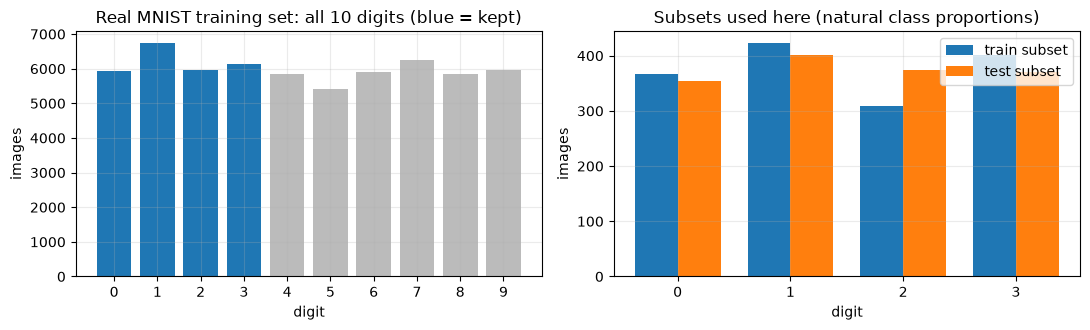

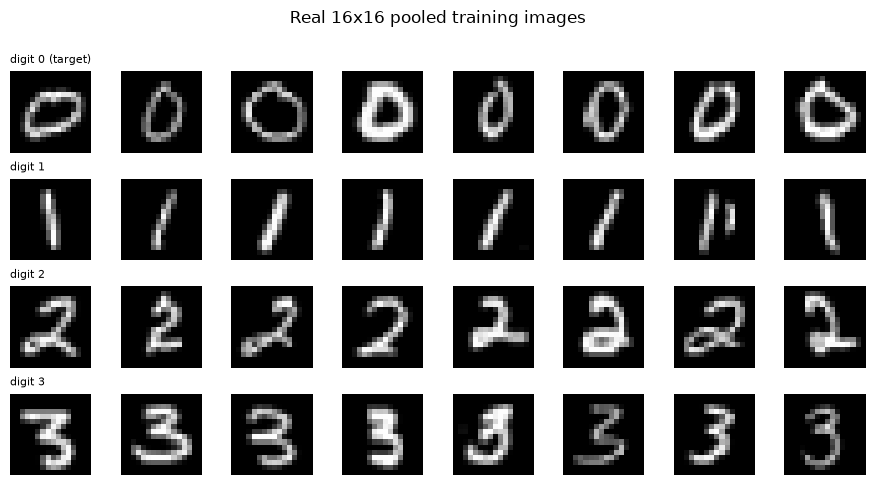

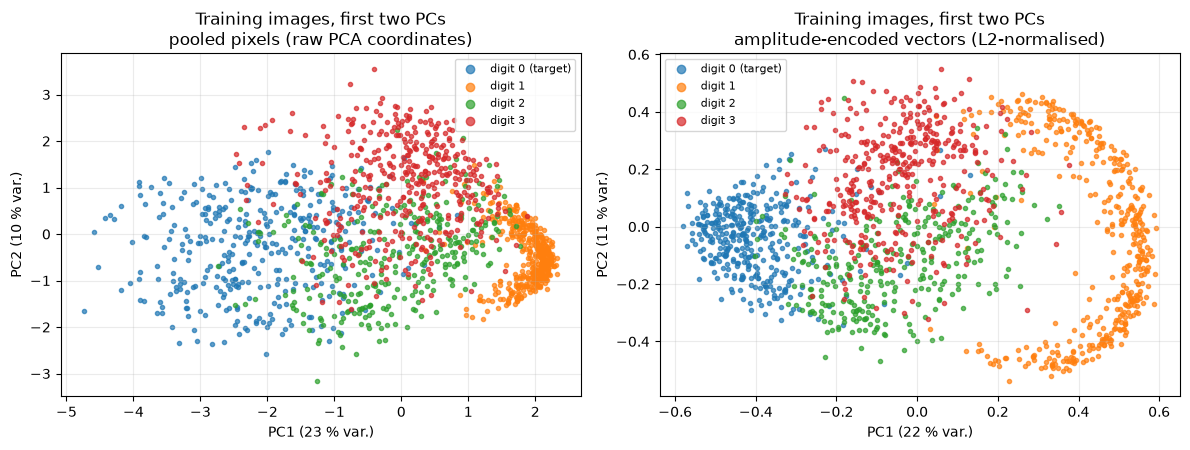

In [5]:
print("Original MNIST: train", x_tr_all.shape, "test", x_te_all.shape, "| pixel type", x_tr_all.dtype, "range", x_tr_all.min(), "-", x_tr_all.max())
print("Original label values (full training set):", dict(zip(*[a.tolist() for a in np.unique(y_tr_all, return_counts=True)])))
print("Original label values (full test set)    :", dict(zip(*[a.tolist() for a in np.unique(y_te_all, return_counts=True)])))
feat_names = [f"px_{r}_{c}" for r in range(16) for c in range(16)]
print(f"\nModel input: {len(feat_names)} features per image (pooled pixel intensities in [0,1]); first names {feat_names[:3]} ... last {feat_names[-1]}")
print("Digits kept for the 4-class task:", list(range(N_CLASSES)), "| attacker target class:", TARGET)
for nm, yy in [("train subset", ytr), ("test subset", yte)]:
    print(f"{nm:13s}", dict(zip(*[a.tolist() for a in np.unique(yy.numpy(), return_counts=True)])))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
cnt_all = np.bincount(y_tr_all, minlength=10)
ax[0].bar(range(10), cnt_all, color=["#1f77b4" if k < N_CLASSES else "#bbbbbb" for k in range(10)])
ax[0].set(title="Real MNIST training set: all 10 digits (blue = kept)", xlabel="digit", ylabel="images"); ax[0].set_xticks(range(10))
cnt_tr = np.bincount(ytr.numpy(), minlength=N_CLASSES); cnt_te = np.bincount(yte.numpy(), minlength=N_CLASSES)
w_ = 0.38
ax[1].bar(np.arange(N_CLASSES) - w_ / 2, cnt_tr, w_, label="train subset"); ax[1].bar(np.arange(N_CLASSES) + w_ / 2, cnt_te, w_, label="test subset")
ax[1].set(title="Subsets used here (natural class proportions)", xlabel="digit", ylabel="images"); ax[1].set_xticks(range(N_CLASSES)); ax[1].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(N_CLASSES, 8, figsize=(9, 1.2 * N_CLASSES))
for c in range(N_CLASSES):
    ii = np.where(ytr.numpy() == c)[0][:8]
    for k, i in enumerate(ii):
        ax[c, k].imshow(Xtr[i, 0], cmap="gray", vmin=0, vmax=1); ax[c, k].axis("off")
    ax[c, 0].set_title(f"digit {c}" + (" (target)" if c == TARGET else ""), fontsize=8, loc="left")
fig.suptitle("Real 16x16 pooled training images", y=1.0); plt.tight_layout(); plt.show()

# 2-D projections of the REAL training images, coloured by ground-truth digit; PCA fitted on the training split only
A_tr = Xtr.flatten(1).numpy(); A_te = Xte.flatten(1).numpy()
amp = lambda M: M / np.linalg.norm(M, axis=1, keepdims=True)
cols = plt.cm.tab10(np.arange(10))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for k, (nm, ftr) in enumerate([("pooled pixels (raw PCA coordinates)", A_tr), ("amplitude-encoded vectors (L2-normalised)", amp(A_tr))]):
    pca_v = PCA(n_components=2, random_state=SEED).fit(ftr)
    Z = pca_v.transform(ftr)
    for c in range(N_CLASSES):
        m = ytr.numpy() == c
        ax[k].scatter(Z[m, 0], Z[m, 1], s=9, color=cols[c], alpha=0.7, label=f"digit {c}" + (" (target)" if c == TARGET else ""))
    ax[k].set(title=f"Training images, first two PCs\n{nm}", xlabel=f"PC1 ({100 * pca_v.explained_variance_ratio_[0]:.0f} % var.)", ylabel=f"PC2 ({100 * pca_v.explained_variance_ratio_[1]:.0f} % var.)")
    ax[k].legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()

## 2. Classical baseline on the identical inputs

A yardstick before any quantum number: a random forest and an RBF support-vector machine trained on exactly the same 256 pooled pixels (L2-normalised like the quantum amplitudes) and the same train / test images.
They are *clean* models; they say how hard the 4-class task is. (Section 12 later poisons them with the same data.)

In [6]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(amp(A_tr), ytr.numpy())
svm = SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED).fit(amp(A_tr), ytr.numpy())
base = {"RandomForest": 100 * (rf.predict(amp(A_te)) == yte.numpy()).mean(), "SVC (rbf)": 100 * (svm.predict(amp(A_te)) == yte.numpy()).mean()}
print({k: round(v, 2) for k, v in base.items()}, f"| {time.time() - t0:.1f} s")

{'RandomForest': np.float64(98.13), 'SVC (rbf)': np.float64(98.8)} | 6.2 s


## 3. The building blocks

**Simulator.** The paper simulates its circuits with PennyLane. Here every circuit exists twice: as a PennyLane `QNode` (used for the circuit drawings and for correctness checks) and as a compact exact PyTorch state-vector
simulator (used for training, because it is much faster on a CPU and differentiable in PyTorch). The two are checked to agree to 1e-4 in the circuit section further below.

**Six circuits.** The *victims* QNN1, QNN2, QNN3 (the attack never sees them) and the attacker's *pool* QNN-A, QNN-B, QNN-C. One layer is a block of single-qubit rotations on all 8 qubits and an entangling block;
the table printed by the next cell lists the gates. The output is the Pauli-Z expectation of qubits 0-3, i.e. four class logits.

**The attack code** (`train_qnn`, `Generator`, `train_quap`, ...) follows Algorithm 1; read the docstrings and the `# CHOICE` comments.

In [7]:
NQ = 8
DIM = 2 ** NQ                          # 256 amplitudes = one 16x16 image

# ------------------------------------------------------------------------------------------------
# Architectures. One layer = rotation block (one gate kind after the other on every qubit) and an
# entangling block, in the order given by "order". "w" has shape (L, NQ, n_rot [+1 for RZZ angles]).
#   QNN1 / QNN2 / QNN3 : the three VICTIM families of the paper (refs [42], [43], [44])
#   QNN-A / -B / -C    : the three members of the attacker's QNN pool (Fig. 3/4 of the paper, wiring not given)
# ------------------------------------------------------------------------------------------------
ARCHS = {
    "QNN1":  dict(rot="ZYZ", ent="cnot_range",  order="rot_ent", ref="circuit-centric classifier (Schuld 2020): general rotation + CNOT(q, q+r), r changes with the layer"),
    "QNN2":  dict(rot="XYZ", ent="cnot_ring",   order="ent_rot", ref="VQC of Chen et al. 2020: CNOT ring, then RX-RY-RZ on every qubit"),
    "QNN3":  dict(rot="YZ",  ent="cz_ladder",   order="rot_ent", ref="hardware-efficient ansatz (Manzano 2023): RY-RZ + CZ ladder"),
    "QNN-A": dict(rot="XZ",  ent="cnot_ladder", order="rot_ent", ref="pool member A: RX-RZ + CNOT ladder"),
    "QNN-B": dict(rot="YZY", ent="cz_ring",     order="rot_ent", ref="pool member B: RY-RZ-RY + CZ ring"),
    "QNN-C": dict(rot="Y",   ent="rzz_ring",    order="rot_ent", ref="pool member C: RY + parametrised ZZ (Ising) ring"),
}

def ent_pairs(arch, l):
    e = ARCHS[arch]["ent"]
    if e == "cnot_range":
        r = (l % (NQ - 1)) + 1
        return [(q, (q + r) % NQ) for q in range(NQ)]
    if e in ("cnot_ring", "cz_ring", "rzz_ring"):
        return [(q, (q + 1) % NQ) for q in range(NQ)]
    return [(q, q + 1) for q in range(NQ - 1)]                  # ladders (open chain)

def n_params_per_qubit(arch):
    return len(ARCHS[arch]["rot"]) + (1 if ARCHS[arch]["ent"] == "rzz_ring" else 0)

def _bits(j, q):                       # value of qubit q (wire 0 = most significant bit) in basis state j
    return (j >> (NQ - 1 - q)) & 1

_PERM_CACHE, _CZ_CACHE = {}, {}
def cnot_src(pairs):
    """Permutation of a sequence of CNOT(control, target) gates: new_psi[k] = psi[src[k]]."""
    key = tuple(pairs)
    if key not in _PERM_CACHE:
        src = np.arange(DIM)
        for j in range(DIM):
            bits = [_bits(j, q) for q in range(NQ)]
            for c, t in pairs:
                if bits[c]:
                    bits[t] ^= 1
            k = 0
            for q in range(NQ):
                k = (k << 1) | bits[q]
            src[k] = j
        _PERM_CACHE[key] = torch.tensor(src, dtype=torch.long)
    return _PERM_CACHE[key]

def cz_sign(pairs):
    key = tuple(pairs)
    if key not in _CZ_CACHE:
        s = np.ones(DIM)
        for j in range(DIM):
            for c, t in pairs:
                if _bits(j, c) and _bits(j, t):
                    s[j] = -s[j]
        _CZ_CACHE[key] = torch.tensor(s, dtype=torch.complex64)
    return _CZ_CACHE[key]

ZZ_RING = torch.tensor([[(1 - 2 * _bits(j, q)) * (1 - 2 * _bits(j, (q + 1) % NQ)) for q in range(NQ)] for j in range(DIM)], dtype=torch.float32)   # (256, 8)
Z_SIGN = torch.tensor([[1 - 2 * _bits(j, q) for q in range(N_CLASSES)] for j in range(DIM)], dtype=torch.float32)                              # (256, 4)

def _rot(kind, t):
    """Batched single-qubit rotation RX/RY/RZ; t has any shape S, result S + (2, 2) complex64."""
    c, s = torch.cos(t / 2), torch.sin(t / 2); z = torch.zeros_like(t)
    if kind == "X":
        m = torch.stack([c + 0j, -1j * s, -1j * s, c + 0j], -1)
    elif kind == "Y":
        m = torch.stack([c + 0j, -s + 0j, s + 0j, c + 0j], -1)
    else:
        e = torch.exp(-0.5j * t); m = torch.stack([e, z + 0j, z + 0j, e.conj()], -1)
    return m.reshape(*t.shape, 2, 2)

def _kron_tree(m):
    """m: (L, 8, 2, 2) -> (L, 256, 256): Kronecker product over the qubit axis (wire 0 = most significant)."""
    while m.shape[1] > 1:
        a, b = m[:, 0::2], m[:, 1::2]
        m = torch.einsum("lqij,lqkm->lqikjm", a, b).reshape(m.shape[0], m.shape[1] // 2, a.shape[2] * b.shape[2], a.shape[3] * b.shape[3])
    return m[:, 0]

def rot_unitaries(w, arch):
    rot = ARCHS[arch]["rot"]
    us = _rot(rot[0], w[..., 0])
    for k in range(1, len(rot)):
        us = _rot(rot[k], w[..., k]) @ us                       # gate k acts after gate k-1
    return _kron_tree(us)

def qnn_state(x, w, arch):
    """x: (B,256) real (image pixels), w: (L,8,n_par). Returns the post-ansatz state (B,256) complex64:
    amplitude encoding (L2 normalisation), then L layers of the chosen ansatz."""
    psi = (x / x.norm(dim=1, keepdim=True).clamp_min(1e-8)).to(torch.complex64)
    spec = ARCHS[arch]; L = w.shape[0]
    Us = rot_unitaries(w, arch).unbind(0)
    for l in range(L):
        pairs = ent_pairs(arch, l)
        def ent(p):
            if spec["ent"].startswith("cnot"):
                return torch.index_select(p, 1, cnot_src(pairs))
            if spec["ent"].startswith("cz"):
                return p * cz_sign(pairs)
            theta = w[l, :, len(spec["rot"])]                   # RZZ ring: diagonal phase exp(-i/2 sum_q theta_q Z_q Z_q+1)
            return p * torch.exp(-0.5j * (ZZ_RING @ theta)).to(torch.complex64)
        if spec["order"] == "rot_ent":
            psi = ent(psi @ Us[l].T)
        else:
            psi = ent(psi) @ Us[l].T
    return psi

def logits_from_state(psi):
    return LOGIT_SCALE * ((psi.real ** 2 + psi.imag ** 2) @ Z_SIGN)        # <Z_q> of qubits 0..3, scaled

def qnn_logits(x16, w, arch):
    return logits_from_state(qnn_state(x16.flatten(1), w, arch))

def init_weights(arch, L, seed):
    g = torch.Generator().manual_seed(seed)
    return (torch.rand(L, NQ, n_params_per_qubit(arch), generator=g) * 2 * np.pi).requires_grad_(True)     # CHOICE: uniform [0, 2 pi)

# ---------------- the same circuits as PennyLane QNodes (drawings + equivalence check) -------------
_GATE = {"X": qml.RX, "Y": qml.RY, "Z": qml.RZ}
def make_pl_qnn(arch, L):
    spec = ARCHS[arch]
    dev = qml.device("default.qubit", wires=NQ)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, w):
        qml.AmplitudeEmbedding(x, wires=range(NQ), normalize=True)
        for l in range(L):
            pairs = ent_pairs(arch, l)
            def rot_block():
                for q in range(NQ):
                    for k, kind in enumerate(spec["rot"]):
                        _GATE[kind](w[l, q, k], wires=q)
            def ent_block():
                if spec["ent"].startswith("cnot"):
                    for c, t in pairs: qml.CNOT(wires=[c, t])
                elif spec["ent"].startswith("cz"):
                    for c, t in pairs: qml.CZ(wires=[c, t])
                else:
                    for q, (c, t) in enumerate(pairs): qml.IsingZZ(w[l, q, len(spec["rot"])], wires=[c, t])
            if spec["order"] == "rot_ent":
                rot_block(); ent_block()
            else:
                ent_block(); rot_block()
        return [qml.expval(qml.PauliZ(i)) for i in range(N_CLASSES)]
    return circuit

In [8]:
# ---------------- victim / surrogate training ----------------
def train_qnn(arch, L, X, y, epochs, seed, lr=None, log=0):
    """Adam training of one QNN (cross-entropy on LOGIT_SCALE x <Z>), batch BATCH. Returns the trained angles."""
    lr = lr or LR_QNN
    rng = np.random.default_rng(seed)
    w = init_weights(arch, L, seed)
    opt = torch.optim.Adam([w], lr=lr)
    n = len(X)
    for ep in range(epochs):
        idx = rng.permutation(n); tot = 0.0; nb = 0
        for s in range(0, n - BATCH + 1, BATCH):
            b = idx[s:s + BATCH]
            loss = F.cross_entropy(qnn_logits(X[b], w, arch), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item(); nb += 1
        if log and ((ep + 1) % log == 0 or ep == 0):
            print(f"    epoch {ep + 1:3d}/{epochs}  train loss {tot / max(nb, 1):.3f}", flush=True)
    return w.detach()

@torch.no_grad()
def predict(arch, w, X, bs=500):
    return torch.cat([qnn_logits(X[i:i + bs], w, arch).argmax(1) for i in range(0, len(X), bs)])

# ---------------- triggers ----------------
def add_delta(x, delta):                       # additive universal trigger (QUAP, Q-FGSM): x' = clip(x + delta, 0, 1)
    return (x + delta).clamp(0, 1)

def add_patch(x, size=PATCH):                  # BadNets patch: size x size white square in the bottom-right corner
    x = x.clone(); x[..., -size:, -size:] = 1.0
    return x

def poison(X, y, trigger_fn, rate, seed):
    """Data poisoning: a fraction `rate` of the WHOLE training set (drawn among non-target images) gets the trigger and the target label."""
    r = np.random.default_rng(seed)
    cand = np.where(y.numpy() != TARGET)[0]
    idx = r.choice(cand, int(round(rate * len(X))), replace=False)
    Xp, yp = X.clone(), y.clone()
    Xp[idx] = trigger_fn(X[idx]); yp[idx] = TARGET
    return Xp, yp, idx

def evaluate(arch, w, Xte, yte, trigger_fn=None):
    """CA = clean test accuracy; ASR = share of NON-target test images classified as the target class once the trigger is added."""
    ca = 100 * (predict(arch, w, Xte) == yte).float().mean().item()
    if trigger_fn is None:
        return dict(CA=ca, ASR=float("nan"))
    nt = yte != TARGET
    asr = 100 * (predict(arch, w, trigger_fn(Xte[nt])) == TARGET).float().mean().item()
    return dict(CA=ca, ASR=asr)

# ---------------- QUAP generator (hybrid generative model: classical CNN generator + QNN pool) ----------------
class Generator(nn.Module):
    """Deep convolutional generator: 3 transposed-conv blocks, kernel 4, stride 1 then 2, 2, LeakyReLU(0.2).
    z (Z_DIM x 1 x 1) -> 4x4 -> 8x8 -> 16x16 ; tanh and the factor EPS enforce ||delta||_inf <= EPS."""
    def __init__(self, zdim=Z_DIM, eps=EPS):
        super().__init__()
        self.eps = eps
        self.net = nn.Sequential(nn.ConvTranspose2d(zdim, 128, 4, 1, 0), nn.LeakyReLU(0.2),
                                 nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.LeakyReLU(0.2),
                                 nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())
    def forward(self, z):
        return self.eps * self.net(z)

def margin_loss(logits, t=None, k=K_MARGIN):   # Eq. (4): max( max_{i != t} f_i - f_t , -k )
    t = TARGET if t is None else t
    other = logits.clone(); other[:, t] = -1e9
    return torch.clamp(other.max(1).values - logits[:, t], min=-k)

def nontarget_kl(f_ens, l_k, T, t=None):       # Eq. (5): KL( softmax(f_hat) || softmax(l_hat_k) ), target class removed, temperature T
    t = TARGET if t is None else t
    keep = [i for i in range(f_ens.shape[1]) if i != t]
    logp = F.log_softmax(f_ens[:, keep] / T, 1); logq = F.log_softmax(l_k[:, keep] / T, 1)
    return (logp.exp() * (logp - logq)).sum(1) * T * T        # CHOICE: x T^2 (Hinton's distillation convention) so that T = 80 is not inert

def proj_simplex(v):                           # Euclidean projection onto {w >= 0, sum w = 1}
    u, _ = torch.sort(v, descending=True); css = u.cumsum(0) - 1
    ind = torch.arange(1, len(v) + 1, dtype=v.dtype)
    rho = int((u - css / ind > 0).nonzero().max()) + 1
    return (v - css[rho - 1] / rho).clamp_min(0)

@torch.no_grad()
def fooling_rate(pool, wts, Xnt, delta):
    xa = add_delta(Xnt, delta)
    ens = sum(float(wk) * qnn_logits(xa, wp, a) for wk, (a, wp) in zip(wts, pool))
    return (ens.argmax(1) == TARGET).float().mean().item()

def train_quap(pool, Xnt, epochs, seed, T=TEMP, lam=LAM_KL, use_kl=True, use_minmax=True, log=0, lr=None, fool_thr=FOOL_THR):
    """Algorithm 1: train the generator G so that z -> delta fools the QNN pool; alternate
    outer min over delta (one Adam step on G, w fixed) and inner max over the pool weights w (Eq. 8, projected on the simplex)."""
    g = torch.Generator().manual_seed(seed)
    G = Generator(); z = torch.randn(1, Z_DIM, 1, 1, generator=g)
    opt = torch.optim.Adam(G.parameters(), lr=lr or LR_GEN)
    K = len(pool); wts = torch.ones(K) / K; rng = np.random.default_rng(seed); hist = []
    for ep in range(epochs):
        idx = rng.permutation(len(Xnt)); used = 0
        for s in range(0, len(Xnt) - BATCH + 1, BATCH):
            x = Xnt[idx[s:s + BATCH]]
            delta = G(z); xa = add_delta(x, delta)
            lgs = [qnn_logits(xa, wp, a) for a, wp in pool]
            ens = sum(wts[k] * lgs[k] for k in range(K))
            keep = ens.argmax(1) != TARGET                       # Alg. 1 line 7: only samples that are not yet classified as the target
            if not keep.any():
                continue
            Lk = torch.stack([(margin_loss(lgs[k])[keep].mean() + (lam * nontarget_kl(ens, lgs[k], T)[keep].mean() if use_kl else 0.0)) for k in range(K)])
            loss = (wts * Lk).sum()                              # Eq. (7) with w fixed
            opt.zero_grad(); loss.backward(); opt.step(); used += 1
            if use_minmax:                                       # Eq. (8): gradient ASCENT on w, then projection (Alg. 1 line 16)
                with torch.no_grad():
                    wts = proj_simplex(wts + ALPHA_W * (Lk.detach() - 2 * K * (wts - 1.0 / K)))
        with torch.no_grad():
            d = G(z); f = fooling_rate(pool, wts, Xnt, d)
        hist.append((ep + 1, f, wts.clone().numpy()))
        if log and ((ep + 1) % log == 0 or ep == 0):
            print(f"    generator epoch {ep + 1:3d}/{epochs}  fooling rate {f:.3f}  pool weights {np.round(wts.numpy(), 3)}", flush=True)
        if fool_thr is not None and f >= fool_thr:               # Alg. 1: stop once the fooling rate exceeds the threshold (None = never stop early)
            break
    with torch.no_grad():
        delta = G(z).detach()
    return G, z, delta, hist

def fgsm_trigger(arch, w, Xnt, eps=EPS):
    """Q-FGSM baseline (CHOICE: universal one-step FGSM on ONE surrogate QNN): delta = -eps * sign( mean_x grad_x L_t )."""
    x = Xnt.clone().requires_grad_(True)
    margin_loss(qnn_logits(x, w, arch)).mean().backward()
    return (-eps * x.grad.mean(0, keepdim=True).sign()).detach()

In [9]:
# sanity checks of the building blocks
G0 = Generator(); z0 = torch.randn(1, Z_DIM, 1, 1)
d0 = G0(z0); assert d0.shape == (1, 1, 16, 16) and float(d0.abs().max()) <= EPS + 1e-6
v = proj_simplex(torch.tensor([0.9, 0.5, -0.2])); assert abs(float(v.sum()) - 1) < 1e-6 and bool((v >= 0).all())
print("generator output", tuple(d0.shape), "| max |delta| =", round(float(d0.abs().max()), 3), "<= eps =", EPS, "| generator parameters:", sum(p.numel() for p in G0.parameters()))
print("projection onto the simplex ok:", v.numpy().round(3))
print(pd.DataFrame([dict(circuit=a, role="victim" if a in ("QNN1", "QNN2", "QNN3") else "pool", rotations=s["rot"], entangler=s["ent"], order=s["order"], angles_per_qubit_per_layer=n_params_per_qubit(a), reference=s["ref"]) for a, s in ARCHS.items()]).to_string(index=False))

generator output (1, 1, 16, 16) | max |delta| = 0.08 <= eps = 0.3 | generator parameters: 337089
projection onto the simplex ok: [0.7 0.3 0. ]
circuit   role rotations   entangler   order  angles_per_qubit_per_layer                                                                                           reference
   QNN1 victim       ZYZ  cnot_range rot_ent                           3 circuit-centric classifier (Schuld 2020): general rotation + CNOT(q, q+r), r changes with the layer
   QNN2 victim       XYZ   cnot_ring ent_rot                           3                                    VQC of Chen et al. 2020: CNOT ring, then RX-RY-RZ on every qubit
   QNN3 victim        YZ   cz_ladder rot_ent                           2                                         hardware-efficient ansatz (Manzano 2023): RY-RZ + CZ ladder
  QNN-A   pool        XZ cnot_ladder rot_ent                           2                                                                  pool member A: RX-RZ + CNOT

## 4. Step 1a: the attacker's QNN pool

The attacker trains three differently structured QNNs on clean digits; they are the "discriminators" of the hybrid generative model (Fig. 2). They are **not** the victims: the victims have other circuits, other depths and
other random initial angles. (Paper: three pool members of 20 layers, 10 qubits.)

In [10]:
POOL_ARCHS = ["QNN-A", "QNN-B", "QNN-C"]
pool = []
for i, a in enumerate(POOL_ARCHS):
    t0 = time.time()
    w_ = train_qnn(a, POOL_L, Xtr, ytr, EPOCHS, SEED + 10 + i)              # CHOICE: the attacker's surrogate data = the clean training images
    pool.append((a, w_))
    m = evaluate(a, w_, Xte, yte)
    print(f"{a}: {POOL_L} layers, {w_.numel()} angles, clean test accuracy {m['CA']:.2f} %  ({time.time() - t0:.0f} s)", flush=True)
X_nt = Xtr[ytr != TARGET]                                                    # non-target training images (the attacker perturbs these)
print("non-target training images used by the generator:", len(X_nt))

QNN-A: 20 layers, 320 angles, clean test accuracy 96.20 %  (135 s)


QNN-B: 20 layers, 480 angles, clean test accuracy 96.33 %  (88 s)


QNN-C: 20 layers, 320 angles, clean test accuracy 93.27 %  (109 s)


non-target training images used by the generator: 1133


## 5. Step 1b: generating the trigger (Algorithm 1)

The generator `G` turns a fixed random vector `z` into one 16x16 perturbation `delta` (so the trigger is *universal*: the same pattern for every image). Each round the batch of non-target digits plus `delta`
goes through the three pool QNNs; the loss `L_all` of Eq. (6) is minimised by one Adam step on `G` with the pool weights `w` fixed, then `w` takes one step of gradient **ascent** on Eq. (7)-(8) and is projected back onto the simplex
(so the hardest pool member gets a larger weight, while the term `K ||w - 1/K||^2` keeps the weights near uniform). Training stops when the fooling rate exceeds `FOOL_THR = 0.9`.

    generator epoch   1/15  fooling rate 0.998  pool weights [0.301 0.291 0.407]


generator trained for 1 round(s) in 10 s | max |delta| = 0.300 | fooling rate on the pool (non-target training images) = 0.998


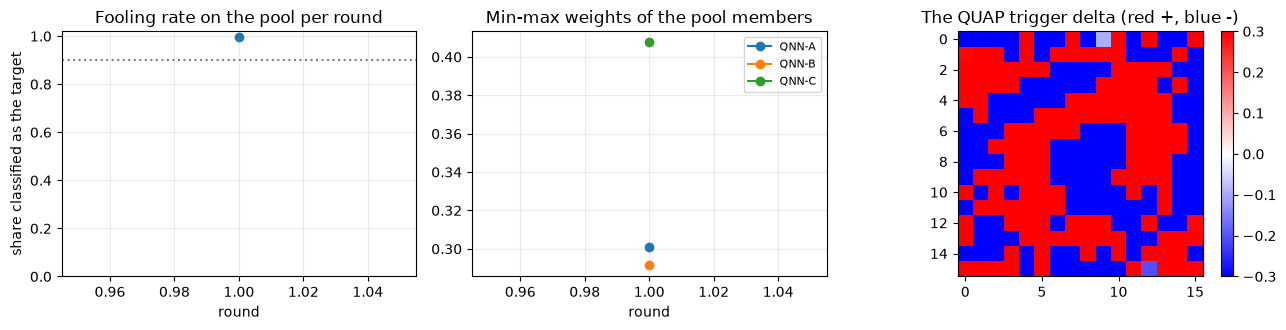

In [11]:
t0 = time.time()
G_quap, z_noise, DELTA, ghist = train_quap(pool, X_nt, GEN_EP, SEED, log=max(1, GEN_EP // 3))
print(f"generator trained for {len(ghist)} round(s) in {time.time() - t0:.0f} s | max |delta| = {float(DELTA.abs().max()):.3f} | "
      f"fooling rate on the pool (non-target training images) = {ghist[-1][1]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot([h[0] for h in ghist], [h[1] for h in ghist], marker="o"); ax[0].axhline(FOOL_THR, color="gray", ls=":")
ax[0].set(title="Fooling rate on the pool per round", xlabel="round", ylabel="share classified as the target", ylim=(0, 1.02))
Wh = np.array([h[2] for h in ghist])
for k, a in enumerate(POOL_ARCHS): ax[1].plot([h[0] for h in ghist], Wh[:, k], marker="o", label=a)
ax[1].set(title="Min-max weights of the pool members", xlabel="round"); ax[1].legend(fontsize=8)
im = ax[2].imshow(DELTA[0, 0], cmap="bwr", vmin=-EPS, vmax=EPS); ax[2].set(title="The QUAP trigger delta (red +, blue -)"); ax[2].grid(False); plt.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.show()

## 6. Step 2: embedding the trigger (and the two baselines)

Poisoning replaces 5 % of the **whole** training set by non-target images that carry the trigger and the label 0. The three triggers compared in Table 1 and Fig. 6 of the paper:

* **QUAP** (this paper): the universal perturbation just generated;
* **Q-FGSM** (baseline): a gradient-sign universal perturbation computed on one surrogate QNN (**CHOICE**, same budget `eps`);
* **Patch** (BadNets baseline): a 3x3 white square in the bottom-right corner.

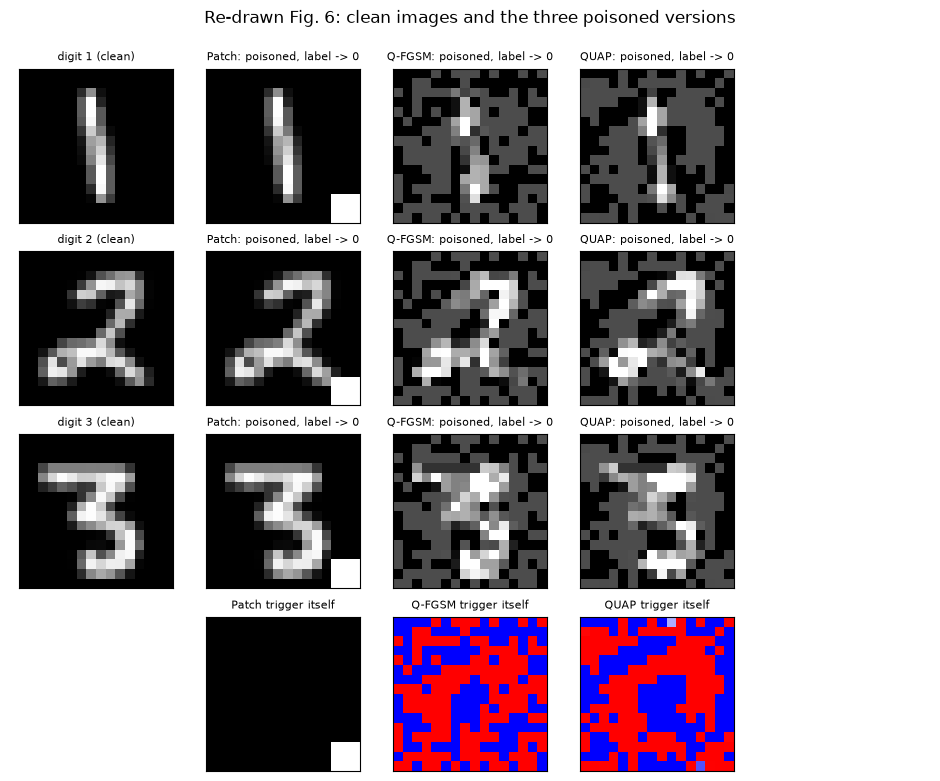

poisoning at rate 0.05: 75 of 1500 training images carry the QUAP trigger and the label 0; their original digits: {1: 25, 2: 22, 3: 28}


In [12]:
DELTA_F = fgsm_trigger(pool[0][0], pool[0][1], X_nt)                          # CHOICE: surrogate = pool member A
TRIG = {"QUAP": lambda x: add_delta(x, DELTA), "Q-FGSM": lambda x: add_delta(x, DELTA_F), "Patch": add_patch}
ATTACKS = list(TRIG)

fig, ax = plt.subplots(4, 5, figsize=(9.5, 7.8))
ex = [int(np.where(ytr.numpy() == c)[0][0]) for c in (1, 2, 3)]
for r, i in enumerate(ex):
    ax[r, 0].imshow(Xtr[i, 0], cmap="gray", vmin=0, vmax=1); ax[r, 0].set_title(f"digit {int(ytr[i])} (clean)", fontsize=8)
    for c, nm in enumerate(["Patch", "Q-FGSM", "QUAP"]):
        ax[r, c + 1].imshow(TRIG[nm](Xtr[i:i + 1])[0, 0], cmap="gray", vmin=0, vmax=1); ax[r, c + 1].set_title(f"{nm}: poisoned, label -> {TARGET}", fontsize=8)
    ax[r, 4].axis("off")
for c, (nm, dl) in enumerate([("Patch", add_patch(torch.zeros(1, 1, 16, 16))[0, 0] ), ("Q-FGSM", DELTA_F[0, 0]), ("QUAP", DELTA[0, 0])]):
    ax[3, c + 1].imshow(dl, cmap="bwr" if nm != "Patch" else "gray", vmin=-EPS if nm != "Patch" else 0, vmax=EPS if nm != "Patch" else 1); ax[3, c + 1].set_title(f"{nm} trigger itself", fontsize=8)
ax[3, 0].axis("off"); ax[3, 4].axis("off")
for a_ in ax.ravel(): a_.set_xticks([]); a_.set_yticks([]); a_.grid(False)
fig.suptitle("Re-drawn Fig. 6: clean images and the three poisoned versions", y=0.995); plt.tight_layout(); plt.show()
Xp_demo, yp_demo, idx_demo = poison(Xtr, ytr, TRIG["QUAP"], POISON_RATE, SEED)
print(f"poisoning at rate {POISON_RATE}: {len(idx_demo)} of {len(Xtr)} training images carry the QUAP trigger and the label {TARGET}; "
      f"their original digits: {dict(zip(*[a.tolist() for a in np.unique(ytr[idx_demo].numpy(), return_counts=True)]))}")

## 7. Victims and Table 1: QUAP against the two baselines

For each unseen victim family the user trains (i) a **clean** model on the clean training set and (ii) one **backdoored** model per attack on the poisoned training set (same circuit, same initial angles, same seed:
only the data differ). Reported: CA on clean test images, ASR on non-target test images with the trigger. The column *clean model, ASR* is the share of triggered images that a model trained **without** poisoning
already assigns to class 0: the natural fooling rate of the trigger (the paper does not report it, and it matters for a UAP trigger).

In [13]:
MODELS = {}        # (arch, layers, attack, rate, seed) -> trained angles
def get_model(arch, L, attack, rate=POISON_RATE, seed=SEED):
    key = (arch, L, attack, 0.0 if attack == "clean" else rate, seed)
    if key not in MODELS:
        if attack == "clean":
            Xp, yp = Xtr, ytr
        else:
            Xp, yp, _ = poison(Xtr, ytr, TRIG[attack], rate, seed)
        MODELS[key] = train_qnn(arch, L, Xp, yp, EPOCHS, seed)
    return MODELS[key]

def cell_row(arch, L, seed=SEED, rate=POISON_RATE, attacks=ATTACKS):
    row = {"victim": f"{arch}-{L}"}
    wc = get_model(arch, L, "clean", seed=seed)
    mc = evaluate(arch, wc, Xte, yte, TRIG["QUAP"])
    row["clean CA"], row["clean model, ASR of QUAP"] = mc["CA"], mc["ASR"]
    for at in attacks:
        m = evaluate(arch, get_model(arch, L, at, rate, seed), Xte, yte, TRIG[at])
        row[f"{at} CA"], row[f"{at} ASR"] = m["CA"], m["ASR"]
    return row

t0 = time.time(); rows1 = []
for arch, L in TABLE1_GRID:
    rows1.append(cell_row(arch, L)); print(f"{arch}-{L}: done ({time.time() - t0:.0f} s)", flush=True)
T1 = pd.DataFrame(rows1).set_index("victim")
print(f"\nTable 1 (this notebook; poisoning rate {POISON_RATE}, eps {EPS}); all values in %")
print(T1.round(2).to_string())

QNN1-10: done (142 s)


QNN2-30: done (591 s)


QNN3-50: done (1421 s)



Table 1 (this notebook; poisoning rate 0.05, eps 0.3); all values in %
         clean CA  clean model, ASR of QUAP  QUAP CA  QUAP ASR  Q-FGSM CA  Q-FGSM ASR  Patch CA  Patch ASR
victim                                                                                                    
QNN1-10     94.80                     76.88    95.87    100.00      96.00       99.83     94.93      90.66
QNN2-30     97.00                     85.51    96.47    100.00      97.13      100.00     97.00      94.59
QNN3-50     97.07                     64.22    96.40     99.91      96.87      100.00     96.40      95.46


## Quantum Circuit Architecture

Every gate-based model that is trained here is drawn below from the very `QNode` that is compared, to 1e-4, with the training simulator, so the drawings show the circuit that is actually executed. A QNN has the three parts of the
paper's Fig. 3: an **encoding** (`AmplitudeEmbedding` of the 256 pooled pixels on 8 qubits), a **parameterised circuit** (the layers) and a **measurement** (Pauli-Z expectation on qubits 0-3 = the four class logits).
The threat model says the attacker cannot change the circuit, so a backdoored QNN is drawn with the *same* gates as the clean one and only different angle values.

* Gate lists (rotation kinds, entangler) are fixed in `ARCHS` above. **Assumptions, because the paper only gives references and a figure:** the rotation sequence and entangler of each circuit; the CNOT range of QNN1 changes with the layer
  `r = (l mod 7) + 1`; the diagonal ring of CZ / ZZ gates of QNN-B / QNN-C; weights uniform in [0, 2 pi); the number of qubits is **8**, not the paper's 10 (256 amplitudes).
* The `AmplitudeEmbedding` box prepares the (normalised) image as the initial state; in the drawings it is shown with the numbers of one real test image.
* The trigger generator is a classical neural network, so it has no circuit; it is summarised in text at the end of this section.

In [14]:
# (a) equivalence: the training simulator reproduces the PennyLane QNode (random 3-layer weights for all six circuits, and one trained model at full depth)
def check_equiv(arch, L, w, X):
    circ = make_pl_qnn(arch, L)
    ref = torch.stack([torch.stack(circ(x, w.detach())) for x in X.flatten(1)]).float()
    mine = qnn_logits(X, w.detach(), arch) / LOGIT_SCALE
    return (ref - mine).abs().max().item()
Xchk = Xte[:4]
errs = {f"{a} (3 random layers)": check_equiv(a, 3, init_weights(a, 3, 1), Xchk) for a in ARCHS}
a1, L1 = TABLE1_GRID[0]
errs[f"{a1}-{L1} backdoored (QUAP), trained angles"] = check_equiv(a1, L1, get_model(a1, L1, "QUAP"), Xchk)
errs[f"{POOL_ARCHS[0]}-{POOL_L} pool member, trained angles"] = check_equiv(POOL_ARCHS[0], POOL_L, pool[0][1], Xchk)
for k, v in errs.items(): print(f"max |PennyLane - simulator| on 4 real test images, {k}: {v:.2e}")
assert max(errs.values()) < 1e-4, errs

max |PennyLane - simulator| on 4 real test images, QNN1 (3 random layers): 2.31e-07
max |PennyLane - simulator| on 4 real test images, QNN2 (3 random layers): 2.31e-07
max |PennyLane - simulator| on 4 real test images, QNN3 (3 random layers): 2.09e-07
max |PennyLane - simulator| on 4 real test images, QNN-A (3 random layers): 1.34e-07
max |PennyLane - simulator| on 4 real test images, QNN-B (3 random layers): 1.79e-07
max |PennyLane - simulator| on 4 real test images, QNN-C (3 random layers): 2.83e-07
max |PennyLane - simulator| on 4 real test images, QNN1-10 backdoored (QUAP), trained angles: 4.47e-07
max |PennyLane - simulator| on 4 real test images, QNN-A-20 pool member, trained angles: 2.53e-07


In [15]:
# (b) qubits, depth, trainable parameters of every circuit that is trained in this notebook
def circuit_facts(arch, L, w, name):
    circ = make_pl_qnn(arch, L); x0 = Xte[0].flatten()
    res = qml.specs(circ)(x0, w.detach())["resources"]
    print(f"{name:34s} qubits = {N_QUBITS}, depth = {res.depth:4d}, gates = {res.num_gates:5d}, trainable angles = {int(w.numel()):5d}, readout = Pauli-Z on qubits 0..{N_CLASSES - 1}")
    return circ, x0
for arch, L in TABLE1_GRID:
    circuit_facts(arch, L, get_model(arch, L, "clean"), f"victim {arch}-{L}")
for (a, w_) in pool:
    circuit_facts(a, POOL_L, w_, f"pool member {a}-{POOL_L}")

def draw(arch, L, w, name, dpi=40):
    circ, x0 = circuit_facts(arch, L, w, name)
    fig, ax = qml.draw_mpl(circ, decimals=1, fontsize=7)(x0, w.detach())
    cols_per_layer = len(ARCHS[arch]["rot"]) + 8
    fig.set_size_inches(min(80, 3 + 0.62 * cols_per_layer * L), 4.6); fig.set_dpi(dpi); fig.suptitle(name, fontsize=14)
    plt.show()

victim QNN1-10                     qubits = 8, depth =   73, gates =   321, trainable angles =   240, readout = Pauli-Z on qubits 0..3


victim QNN2-30                     qubits = 8, depth =  331, gates =   961, trainable angles =   720, readout = Pauli-Z on qubits 0..3


victim QNN3-50                     qubits = 8, depth =  206, gates =  1151, trainable angles =   800, readout = Pauli-Z on qubits 0..3
pool member QNN-A-20               qubits = 8, depth =   86, gates =   461, trainable angles =   320, readout = Pauli-Z on qubits 0..3


pool member QNN-B-20               qubits = 8, depth =  221, gates =   641, trainable angles =   480, readout = Pauli-Z on qubits 0..3
pool member QNN-C-20               qubits = 8, depth =  181, gates =   321, trainable angles =   320, readout = Pauli-Z on qubits 0..3


Clean QNN1-10 (trained angles in rad) qubits = 8, depth =   73, gates =   321, trainable angles =   240, readout = Pauli-Z on qubits 0..3

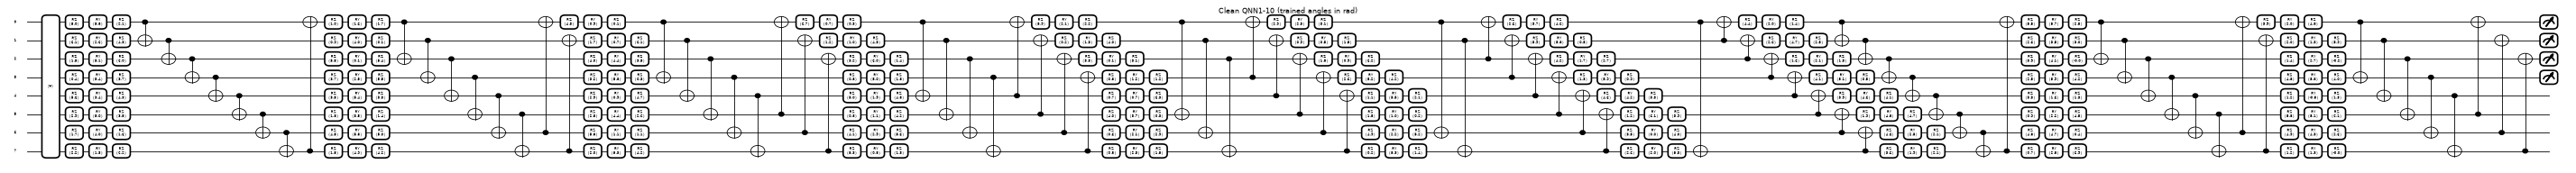

Backdoored QNN1-10 (QUAP-poisoned training, same circuit) qubits = 8, depth =   73, gates =   321, trainable angles =   240, readout = Pauli-Z on qubits 0..3


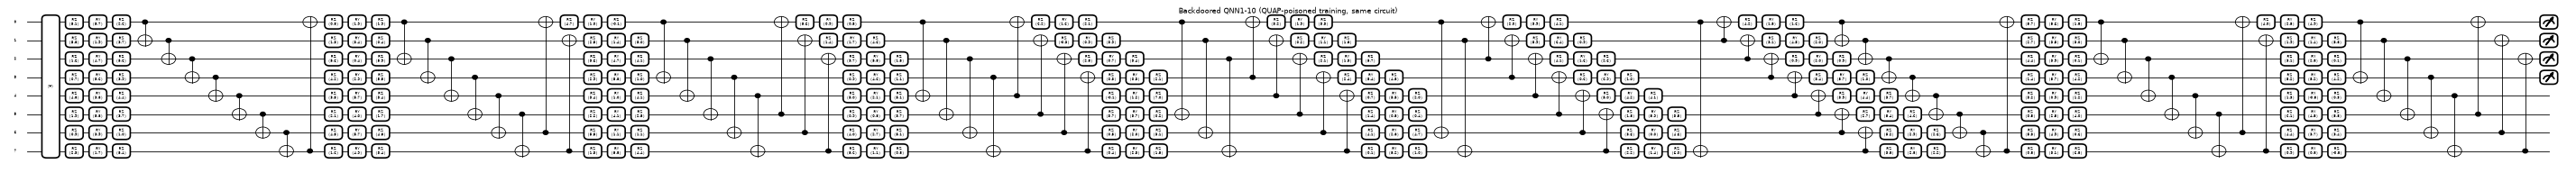

In [16]:
# (c) the executed circuit of the main victim at full depth, clean and backdoored (same gates, different angles)
draw(a1, L1, get_model(a1, L1, "clean"), f"Clean {a1}-{L1} (trained angles in rad)")
draw(a1, L1, get_model(a1, L1, "QUAP"), f"Backdoored {a1}-{L1} (QUAP-poisoned training, same circuit)")

Victim QNN1: encoding + layer 1 + readout qubits = 8, depth =   12, gates =    33, trainable angles =    24, readout = Pauli-Z on qubits 0..3


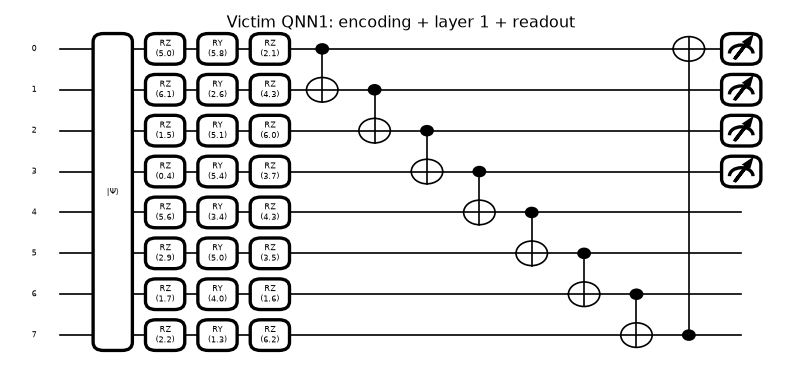

Victim QNN2: encoding + layer 1 + readout qubits = 8, depth =   12, gates =    33, trainable angles =    24, readout = Pauli-Z on qubits 0..3


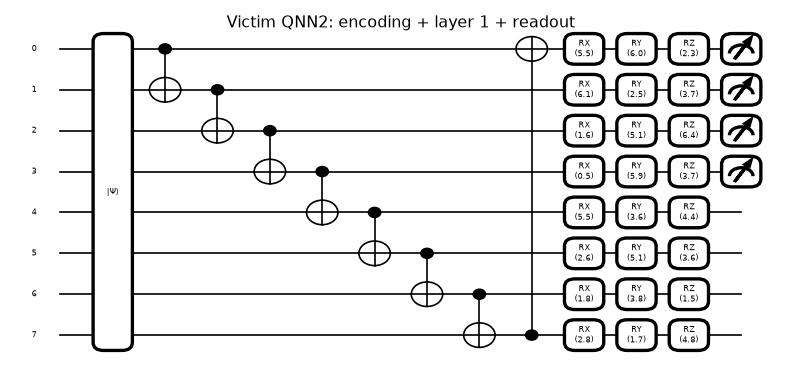

Victim QNN3: encoding + layer 1 + readout qubits = 8, depth =   10, gates =    24, trainable angles =    16, readout = Pauli-Z on qubits 0..3


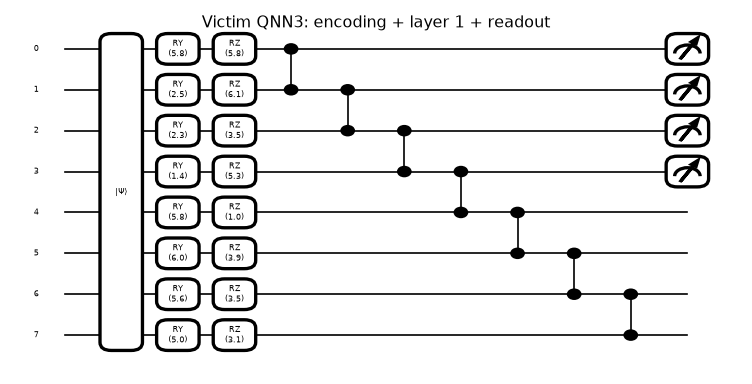

Pool member QNN-A: encoding + layer 1 + readout qubits = 8, depth =   10, gates =    24, trainable angles =    16, readout = Pauli-Z on qubits 0..3


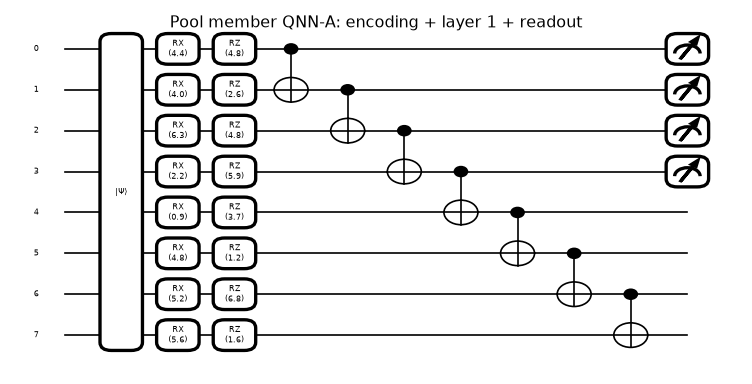

Pool member QNN-B: encoding + layer 1 + readout qubits = 8, depth =   12, gates =    33, trainable angles =    24, readout = Pauli-Z on qubits 0..3


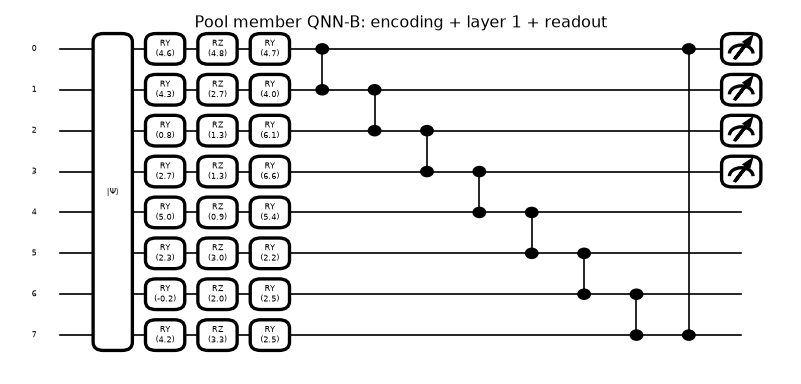

Pool member QNN-C: encoding + layer 1 + readout qubits = 8, depth =   10, gates =    17, trainable angles =    16, readout = Pauli-Z on qubits 0..3


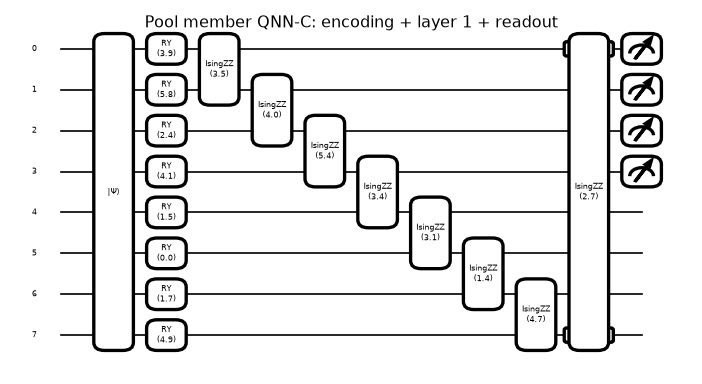


Trigger generator G (classical, no circuit):
Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 128, kernel_size=(4, 4), stride=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): LeakyReLU(negative_slope=0.2)
    (4): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): Tanh()
  )
)
generator parameters: 337089


In [17]:
# (d) one drawing per distinct architecture: encoding + the FIRST layer + measurement (the full circuits repeat this block L times with other angles; QNN1's CNOT range changes with the layer)
for arch, L in TABLE1_GRID:
    draw(arch, 1, get_model(arch, L, "clean")[:1], f"Victim {arch}: encoding + layer 1 + readout", dpi=80)
for (a, w_) in pool:
    draw(a, 1, w_[:1], f"Pool member {a}: encoding + layer 1 + readout", dpi=80)
print("\nTrigger generator G (classical, no circuit):"); print(G_quap)
print("generator parameters:", sum(p.numel() for p in G_quap.parameters()))

## 8. Metrics: CA, ASR and confusion matrices

* **CA**: accuracy of a model on *clean* test images. A successful backdoor keeps it close to the clean model's CA (stealthiness towards the user).
* **ASR**: share of non-target test images that the backdoored model assigns to the target class 0 once the trigger is added.

The confusion matrices put the true digit on the rows and the prediction on the columns. For the attack, the "positive" outcome is the prediction 0 for triggered non-target digits (right-hand panel, first column).

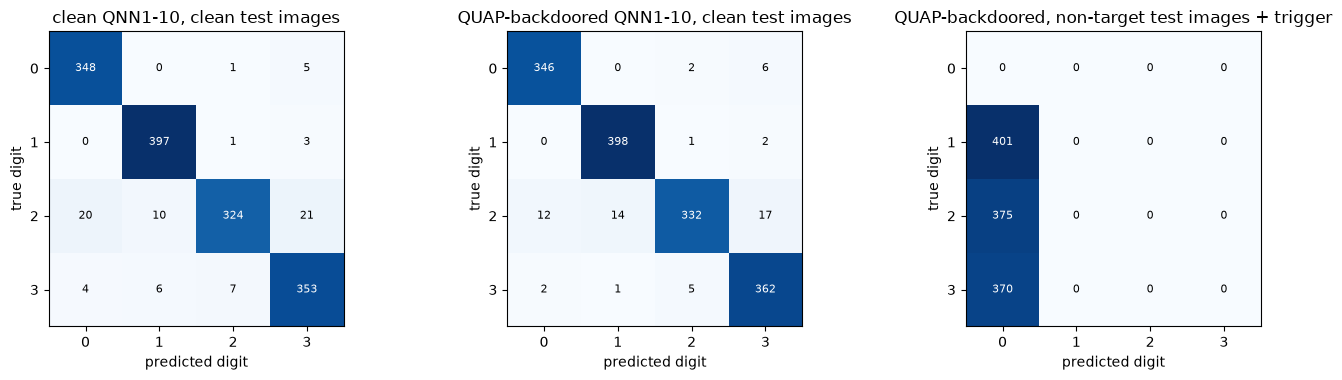

triggered non-target images: 1146/1146 predicted as the target class 0 (ASR 100.00 %); false 'attack' alarms on clean non-target images: 14/1146


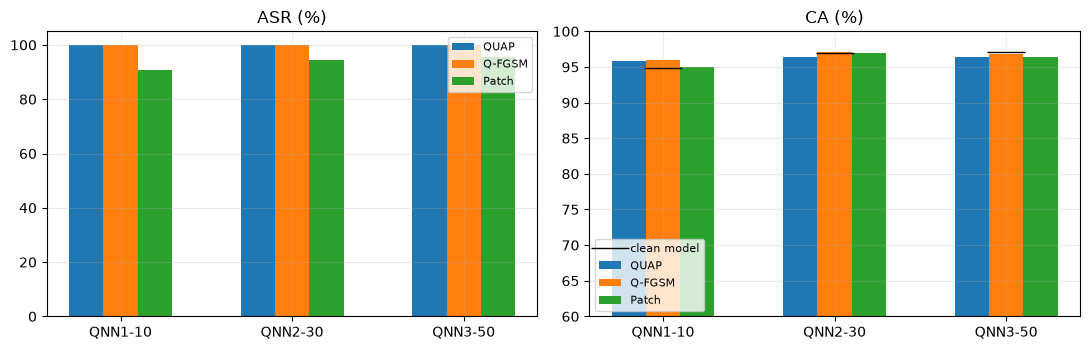

In [18]:
def conf(y, p, k=N_CLASSES):
    M = np.zeros((k, k), int)
    for t, q in zip(y.numpy(), p.numpy()): M[t, q] += 1
    return M

def show_conf(ax, M, title, rows):
    ax.imshow(M, cmap="Blues"); ax.set(title=title, xlabel="predicted digit", ylabel="true digit", xticks=range(N_CLASSES), yticks=range(N_CLASSES), yticklabels=rows); ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]): ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8, color="white" if M[i, j] > M.max() / 2 else "black")

wq = get_model(a1, L1, "QUAP"); wc1 = get_model(a1, L1, "clean")
nt = yte != TARGET
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
show_conf(ax[0], conf(yte, predict(a1, wc1, Xte)), f"clean {a1}-{L1}, clean test images", list(range(N_CLASSES)))
show_conf(ax[1], conf(yte, predict(a1, wq, Xte)), f"QUAP-backdoored {a1}-{L1}, clean test images", list(range(N_CLASSES)))
show_conf(ax[2], conf(yte[nt], predict(a1, wq, TRIG["QUAP"](Xte[nt]))), "QUAP-backdoored, non-target test images + trigger", list(range(N_CLASSES)))
plt.tight_layout(); plt.show()
p_trig = predict(a1, wq, TRIG["QUAP"](Xte[nt]))
tp = int((p_trig == TARGET).sum()); n_nt = int(nt.sum())
print(f"triggered non-target images: {tp}/{n_nt} predicted as the target class 0 (ASR {100 * tp / n_nt:.2f} %); false 'attack' alarms on clean non-target images: "
      f"{int((predict(a1, wq, Xte[nt]) == TARGET).sum())}/{n_nt}")

# bar chart of Table 1
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); xs = np.arange(len(T1)); w_ = 0.2
for k, at in enumerate(ATTACKS):
    ax[0].bar(xs + (k - 1) * w_, T1[f"{at} ASR"], w_, label=at); ax[1].bar(xs + (k - 1) * w_, T1[f"{at} CA"], w_, label=at)
ax[1].plot(xs, T1["clean CA"], "k_", ms=28, label="clean model")
for a_, t in zip(ax, ["ASR (%)", "CA (%)"]): a_.set_xticks(xs); a_.set_xticklabels(T1.index); a_.set_title(t); a_.legend(fontsize=8)
ax[1].set_ylim(60, 100); plt.tight_layout(); plt.show()

## 9. Table 2: depth and pool membership

Paper: with all victims at 20 layers (and with the pool members themselves as victims) the ASR changes only slightly, "marginally better" for pool architectures. Here the pool depth `POOL_L` plays the role of the paper's 20 layers.
A pool member as a victim is a fresh QNN of the same circuit family, with other initial angles, trained on the poisoned data (it is not the attacker's surrogate itself).

In [19]:
t0 = time.time(); rows2 = []
for arch in ["QNN1", "QNN2", "QNN3", "QNN-A", "QNN-B", "QNN-C"]:
    rows2.append(cell_row(arch, POOL_L, attacks=["QUAP"])); print(f"{arch}-{POOL_L}: done ({time.time() - t0:.0f} s)", flush=True)
T2 = pd.DataFrame(rows2).set_index("victim")
print(f"Table 2 (this notebook; QUAP, {POOL_L} layers), values in %")
print(T2.round(2).to_string())

QNN1-20: done (233 s)


QNN2-20: done (511 s)


QNN3-20: done (768 s)


QNN-A-20: done (1030 s)


QNN-B-20: done (1265 s)


QNN-C-20: done (1457 s)


Table 2 (this notebook; QUAP, 20 layers), values in %
          clean CA  clean model, ASR of QUAP  QUAP CA  QUAP ASR
victim                                                         
QNN1-20      96.67                     86.65    96.40     100.0
QNN2-20      96.80                     94.59    97.00     100.0
QNN3-20      96.60                     92.06    96.67     100.0
QNN-A-20     97.07                     97.03    96.80     100.0
QNN-B-20     96.13                     85.51    96.53     100.0
QNN-C-20     93.87                     97.29    94.87     100.0


## 10. Poisoning rate (Table 3, Figs. 8-9)

The poisoning rate `p` is varied on the main victim (QNN1). The paper reports the QUAP ASR rising from 51 % (p = 0.01) to 97 % (p = 0.04) while Q-FGSM and the patch stay below 9 %.
The horizontal line is the *natural fooling rate* of the QUAP trigger on the clean model (rate 0).

p = 0.01: done (166 s)


p = 0.02: done (312 s)


p = 0.03: done (515 s)


p = 0.04: done (681 s)


p = 0.05: done (684 s)


Table 3 (this notebook; victim QNN1-10), values in %
                QUAP CA  QUAP ASR  Q-FGSM CA  Q-FGSM ASR  Patch CA  Patch ASR
poisoning rate                                                               
0.01              96.07     97.82      96.47       96.51     95.73      22.25
0.02              95.60    100.00      96.07       90.23     95.80      42.50
0.03              95.60     99.91      96.07       99.74     94.73      85.17
0.04              96.20    100.00      94.93      100.00     96.47      96.51
0.05              95.87    100.00      96.00       99.83     94.93      90.66
clean QNN1-10: CA 94.80 %, natural ASR of the QUAP trigger 76.88 %


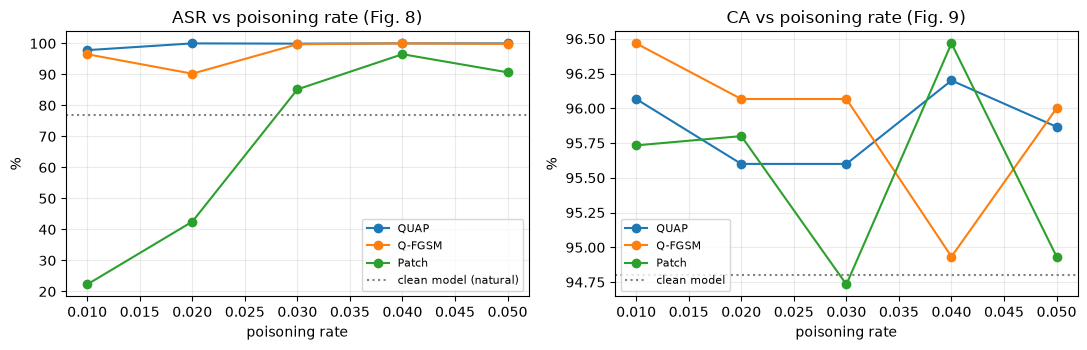


QNN1-10, 3 seeds:
      clean_CA  clean_natural_ASR  QUAP_CA  QUAP_ASR
seed                                                
42       94.80              76.88    95.87     100.0
43       96.33              65.27    95.73      99.3
44       96.13              89.44    96.00     100.0
mean +- std: {'clean_CA': '95.76 +- 0.83', 'clean_natural_ASR': '77.2 +- 12.09', 'QUAP_CA': '95.87 +- 0.13', 'QUAP_ASR': '99.77 +- 0.4'}


In [20]:
t0 = time.time(); rows3 = []
for p in RATES + [POISON_RATE]:
    r_ = {"poisoning rate": p}
    for at in ATTACKS:
        m = evaluate(a1, get_model(a1, L1, at, p), Xte, yte, TRIG[at]); r_[f"{at} CA"], r_[f"{at} ASR"] = m["CA"], m["ASR"]
    rows3.append(r_); print(f"p = {p}: done ({time.time() - t0:.0f} s)", flush=True)
T3 = pd.DataFrame(rows3).sort_values("poisoning rate").set_index("poisoning rate")
clean_nat = evaluate(a1, get_model(a1, L1, "clean"), Xte, yte, TRIG["QUAP"])
print(f"Table 3 (this notebook; victim {a1}-{L1}), values in %"); print(T3.round(2).to_string())
print(f"clean {a1}-{L1}: CA {clean_nat['CA']:.2f} %, natural ASR of the QUAP trigger {clean_nat['ASR']:.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for at in ATTACKS:
    ax[0].plot(T3.index, T3[f"{at} ASR"], marker="o", label=at); ax[1].plot(T3.index, T3[f"{at} CA"], marker="o", label=at)
ax[0].axhline(clean_nat["ASR"], color="gray", ls=":", label="clean model (natural)"); ax[1].axhline(clean_nat["CA"], color="gray", ls=":", label="clean model")
ax[0].set(title="ASR vs poisoning rate (Fig. 8)", xlabel="poisoning rate", ylabel="%"); ax[1].set(title="CA vs poisoning rate (Fig. 9)", xlabel="poisoning rate", ylabel="%")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

# repeated runs: victim initialisation and poisoned subset change with the seed, the trigger stays
if len(SEEDS_REP) > 1:
    reps = []
    for s in SEEDS_REP:
        m = evaluate(a1, get_model(a1, L1, "QUAP", seed=s), Xte, yte, TRIG["QUAP"]); mc = evaluate(a1, get_model(a1, L1, "clean", seed=s), Xte, yte, TRIG["QUAP"])
        reps.append(dict(seed=s, clean_CA=mc["CA"], clean_natural_ASR=mc["ASR"], QUAP_CA=m["CA"], QUAP_ASR=m["ASR"]))
    R = pd.DataFrame(reps).set_index("seed"); print(f"\n{a1}-{L1}, {len(SEEDS_REP)} seeds:"); print(R.round(2).to_string()); print("mean +- std:", (R.mean().round(2).astype(str) + " +- " + R.std().round(2).astype(str)).to_dict())
else:
    print("\n(one seed in FAST_MODE; the full run repeats the main cell with three seeds)")

### Is the large gap to the paper's baselines a learning-rate artefact?

The paper trains with learning rate 1e-3 for 30 epochs on 24 754 images (about 11 600 optimiser steps). Here an epoch has a few dozen steps, so `LR_QNN = 0.05` was chosen (**CHOICE**). To see whether the baselines' ASR depends on the training budget,
the main victim is trained again at smaller learning rates (clean, QUAP-poisoned, patch-poisoned). A model that has not converged shows a low CA, and then neither a high nor a low ASR means much.

In [21]:
rows_lr = []
for lr in LR_DIAG + [LR_QNN]:
    row = {"learning rate": lr}
    for at in ["clean", "QUAP", "Patch"]:
        if lr == LR_QNN: w_ = get_model(a1, L1, at)
        else:
            Xp_l, yp_l = (Xtr, ytr) if at == "clean" else poison(Xtr, ytr, TRIG[at], POISON_RATE, SEED)[:2]
            w_ = train_qnn(a1, L1, Xp_l, yp_l, EPOCHS, SEED, lr=lr)
        m = evaluate(a1, w_, Xte, yte, TRIG["QUAP" if at == "clean" else at])
        row[f"{at} CA"] = m["CA"]; row[f"{at} ASR" + (" (natural, QUAP trigger)" if at == "clean" else "")] = m["ASR"]
    rows_lr.append(row); print(f"lr {lr}: done", flush=True)
TLR = pd.DataFrame(rows_lr).set_index("learning rate"); print(f"{a1}-{L1}, {EPOCHS} epochs, values in %"); print(TLR.round(2).to_string())

lr 0.001: done


lr 0.01: done


lr 0.05: done


QNN1-10, 12 epochs, values in %
               clean CA  clean ASR (natural, QUAP trigger)  QUAP CA  QUAP ASR  Patch CA  Patch ASR
learning rate                                                                                     
0.001             91.07                              48.69    90.53     97.82     90.67      40.23
0.010             96.53                              80.45    95.87    100.00     95.67      81.41
0.050             94.80                              76.88    95.87    100.00     94.93      90.66


## 11. Transferability: why the pool, the KL term and the min-max step (and the temperature, Fig. 7)

The black-box claim is about **transfer**: a trigger optimised on the pool should already push images of *unseen* circuits towards class 0, so that few poisoned samples suffice. We measure it directly, without any poisoning:
the **fooling rate** of a trigger is the share of non-target test images that a **clean victim** (the clean QNN1 / QNN2 / QNN3 of Table 1) assigns to class 0. All generator variants below are trained for the same number of rounds
(`GEN_EP_ABL`, no early stopping); the control is a random +-eps sign pattern of the same size.
The paper's temperature experiment (Fig. 7) asks which `T` makes the KL term most useful; we repeat it with the same transfer measure.

In [22]:
victims_clean = [(a, L, get_model(a, L, "clean")) for a, L in TABLE1_GRID]
def transfer(delta):
    return [100 * (predict(a, w_, add_delta(Xte[nt], delta)) == TARGET).float().mean().item() for a, L, w_ in victims_clean]

rows_t = []
def add_variant(name, delta, ep=None):
    f = transfer(delta); rows_t.append({"trigger": name, **{f"fool {a}-{L}": v for (a, L, _), v in zip(victims_clean, f)}, "mean": float(np.mean(f))})

g_ = torch.Generator().manual_seed(SEED)
add_variant("random +-eps signs (control)", EPS * torch.sign(torch.randn(1, 1, 16, 16, generator=g_)))
add_variant("Q-FGSM (one surrogate)", DELTA_F)
add_variant(f"QUAP main run ({len(ghist)} round(s), paper stopping rule)", DELTA)
t0 = time.time()
for name, pl, kw in [("QUAP, full pool + KL + min-max", pool, {}), ("QUAP w/o non-target KL", pool, dict(use_kl=False)),
                     ("QUAP w/o min-max (uniform weights)", pool, dict(use_minmax=False)), ("QUAP, single surrogate (QNN-A only)", pool[:1], {})]:
    _, _, d_, _ = train_quap(pl, X_nt, GEN_EP_ABL, SEED, fool_thr=None, **kw)
    add_variant(f"{name} ({GEN_EP_ABL} rounds)", d_); print(f"{name}: {time.time() - t0:.0f} s", flush=True)
TR = pd.DataFrame(rows_t).set_index("trigger"); print("\nFooling rate of the triggers on CLEAN victims (no poisoning), %"); print(TR.round(1).to_string())

QUAP, full pool + KL + min-max: 41 s


QUAP w/o non-target KL: 83 s


QUAP w/o min-max (uniform weights): 126 s


QUAP, single surrogate (QNN-A only): 142 s



Fooling rate of the triggers on CLEAN victims (no poisoning), %
                                                 fool QNN1-10  fool QNN2-30  fool QNN3-50  mean
trigger                                                                                        
random +-eps signs (control)                              8.7           3.4           3.0   5.0
Q-FGSM (one surrogate)                                   59.8          66.1          56.6  60.8
QUAP main run (1 round(s), paper stopping rule)          76.9          85.5          64.2  75.5
QUAP, full pool + KL + min-max (5 rounds)                77.4          81.2          74.7  77.7
QUAP w/o non-target KL (5 rounds)                        60.0          39.9          48.3  49.4
QUAP w/o min-max (uniform weights) (5 rounds)            59.6          88.7          89.6  79.3
QUAP, single surrogate (QNN-A only) (5 rounds)           20.2          56.0          38.0  38.1


T = 1.0: mean fooling rate 61.3 %


T = 20.0: mean fooling rate 72.5 %


T = 80.0: mean fooling rate 46.8 %


T = 140.0: mean fooling rate 63.8 %


       fool QNN1-10  fool QNN2-30  fool QNN3-50  mean
T                                                    
1.0            54.6          56.5          72.9  61.3
20.0           73.8          68.8          74.8  72.5
80.0           32.7          68.0          39.8  46.8
140.0          72.3          45.9          73.1  63.8


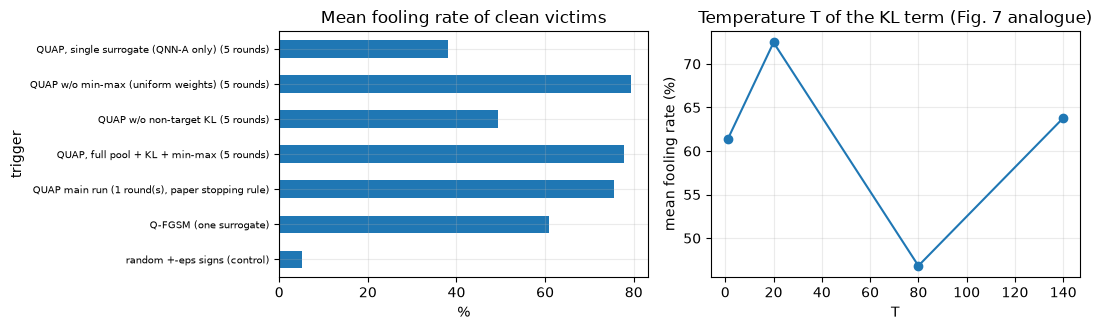

In [23]:
# Fig. 7 analogue: the temperature T of the non-target KL term
rows_T = []
for T_ in TEMP_SWEEP:
    _, _, d_, _ = train_quap(pool, X_nt, GEN_EP_ABL, SEED, T=T_, fool_thr=None)
    f = transfer(d_); rows_T.append(dict(T=T_, **{f"fool {a}-{L}": v for (a, L, _), v in zip(victims_clean, f)}, mean=float(np.mean(f)))); print(f"T = {T_}: mean fooling rate {np.mean(f):.1f} %", flush=True)
TT = pd.DataFrame(rows_T).set_index("T"); print(TT.round(1).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
TR["mean"].plot.barh(ax=ax[0]); ax[0].set(title="Mean fooling rate of clean victims", xlabel="%"); ax[0].tick_params(axis="y", labelsize=7)
ax[1].plot(TT.index, TT["mean"], marker="o"); ax[1].set(title="Temperature T of the KL term (Fig. 7 analogue)", xlabel="T", ylabel="mean fooling rate (%)")
plt.tight_layout(); plt.show()

## 12. Detection: STRIP and spectral signatures (Figs. 10-11), and classical models under the same poisoning

The paper tests the backdoored QNN against two detectors on 100 samples (50 clean, 50 poisoned).

* **Spectral signatures** [Tran et al.]: take a representation of the samples (here the post-ansatz quantum state, real and imaginary parts: **CHOICE**), centre it, project on the top singular vector; the squared projection is the outlier score.
  Poisoned samples should have larger scores. We report the AUROC of "score separates poisoned from clean" (0.5 = no detection) in the paper's 50 + 50 protocol, and in the textbook protocol (all training samples labelled 0, poisoned ones are the relabelled images).
* **STRIP** [Gao et al.]: superimpose each input with random clean images and look at the entropy of the prediction. A backdoor input stays classified as the target, so its entropy is low. The overlap of the entropy histograms of clean and
  poisoned inputs measures how hard detection is (1 = identical, 0 = disjoint); the AUROC of "low entropy => poisoned" is reported too.

Finally an SVM and a random forest (the classical baselines of section 2) are trained on the same QUAP-poisoned data.

backdoored QNN1-10: prediction on the 50 poisoned evaluation images -> target class: 100 %, on the 50 clean evaluation images -> target class: 2 %


spectral signatures, AUROC: paper protocol (50+50 test samples) = 0.512 | training samples labelled 0 (75 poisoned of 442) = 0.230
mean outlier score: clean 0.112 vs poisoned 0.106


STRIP (100 superimpositions, 6 s): mean entropy clean 0.862 vs poisoned 0.857 | histogram overlap 0.64 | AUROC 0.501


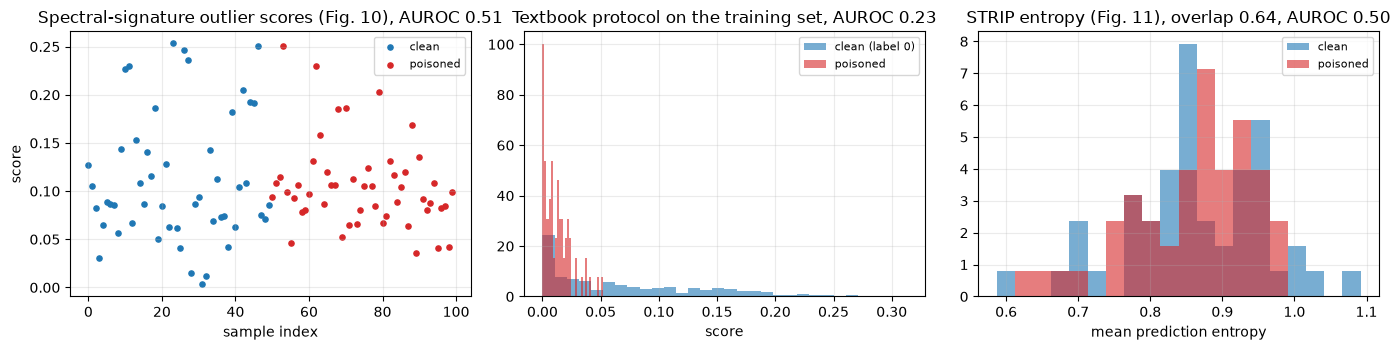


Classical models under the same QUAP trigger and 5 % poisoning, %
              clean CA  clean model, ASR of QUAP  poisoned CA  poisoned ASR
model                                                                      
RandomForest     98.13                     88.48        98.13         100.0
SVC (rbf)        98.80                     62.57        98.93         100.0


In [24]:
# ---------- defender's view of the QUAP-backdoored main victim ----------
wq = get_model(a1, L1, "QUAP")
n_ = N_DEF // 2
r_ = np.random.default_rng(SEED + 5)
ix_nt = r_.permutation(np.where(nt.numpy())[0])
ix_clean, ix_pois, ix_pool = ix_nt[:n_], ix_nt[n_:2 * n_], r_.permutation(len(Xte))[-300:]
X_clean_eval, X_pois_eval = Xte[ix_clean], TRIG["QUAP"](Xte[ix_pois])
print(f"backdoored {a1}-{L1}: prediction on the {n_} poisoned evaluation images -> target class: {100 * (predict(a1, wq, X_pois_eval) == TARGET).float().mean().item():.0f} %, "
      f"on the {n_} clean evaluation images -> target class: {100 * (predict(a1, wq, X_clean_eval) == TARGET).float().mean().item():.0f} %")

@torch.no_grad()
def rep(arch, w_, X):
    psi = qnn_state(X.flatten(1), w_, arch); return torch.cat([psi.real, psi.imag], 1).numpy()
def spectral_scores(R):
    Rc = R - R.mean(0); _, _, Vt = np.linalg.svd(Rc, full_matrices=False); return (Rc @ Vt[0]) ** 2

# (a) the paper's protocol: 50 clean + 50 poisoned test samples
R_ = rep(a1, wq, torch.cat([X_clean_eval, X_pois_eval])); sc_a = spectral_scores(R_); lab_a = np.r_[np.zeros(n_), np.ones(n_)]
auc_spec_a = roc_auc_score(lab_a, sc_a)
# (b) textbook protocol: the training samples that carry the label 0 in the poisoned training set
Xp_, yp_, ip_ = poison(Xtr, ytr, TRIG["QUAP"], POISON_RATE, SEED)
m0 = (yp_ == TARGET).numpy(); R0 = rep(a1, wq, Xp_[m0]); sc_b = spectral_scores(R0); lab_b = np.isin(np.where(m0)[0], ip_).astype(int)
auc_spec_b = roc_auc_score(lab_b, sc_b)
print(f"spectral signatures, AUROC: paper protocol (50+50 test samples) = {auc_spec_a:.3f} | training samples labelled {TARGET} ({lab_b.sum()} poisoned of {len(lab_b)}) = {auc_spec_b:.3f}")
print(f"mean outlier score: clean {sc_a[lab_a == 0].mean():.3f} vs poisoned {sc_a[lab_a == 1].mean():.3f}")

# STRIP
@torch.no_grad()
def strip_entropy(arch, w_, X, clean_pool, n_pert, seed):
    r = np.random.default_rng(seed); H = []
    for x in X:
        js = r.choice(len(clean_pool), n_pert, replace=False)
        p = F.softmax(qnn_logits(0.5 * x[None] + 0.5 * clean_pool[js], w_, arch), 1)
        H.append(float((-(p * torch.log(p + 1e-12)).sum(1)).mean()))
    return np.array(H)
t0 = time.time()
H_c = strip_entropy(a1, wq, X_clean_eval, Xte[ix_pool], STRIP_N, 1); H_p = strip_entropy(a1, wq, X_pois_eval, Xte[ix_pool], STRIP_N, 2)
bins = np.linspace(min(H_c.min(), H_p.min()), max(H_c.max(), H_p.max()) + 1e-9, 21)
hc, _ = np.histogram(H_c, bins); hp, _ = np.histogram(H_p, bins)
overlap = float(np.minimum(hc / hc.sum(), hp / hp.sum()).sum()); auc_strip = roc_auc_score(np.r_[np.zeros(n_), np.ones(n_)], -np.r_[H_c, H_p])
print(f"STRIP ({STRIP_N} superimpositions, {time.time() - t0:.0f} s): mean entropy clean {H_c.mean():.3f} vs poisoned {H_p.mean():.3f} | histogram overlap {overlap:.2f} | AUROC {auc_strip:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].scatter(range(n_), sc_a[:n_], s=14, label="clean"); ax[0].scatter(range(n_, 2 * n_), sc_a[n_:], s=14, color="tab:red", label="poisoned")
ax[0].set(title=f"Spectral-signature outlier scores (Fig. 10), AUROC {auc_spec_a:.2f}", xlabel="sample index", ylabel="score"); ax[0].legend(fontsize=8)
ax[1].hist(sc_b[lab_b == 0], bins=30, alpha=0.6, density=True, label="clean (label 0)"); ax[1].hist(sc_b[lab_b == 1], bins=30, alpha=0.6, density=True, color="tab:red", label="poisoned")
ax[1].set(title=f"Textbook protocol on the training set, AUROC {auc_spec_b:.2f}", xlabel="score"); ax[1].legend(fontsize=8)
ax[2].hist(H_c, bins, alpha=0.6, density=True, label="clean"); ax[2].hist(H_p, bins, alpha=0.6, density=True, color="tab:red", label="poisoned")
ax[2].set(title=f"STRIP entropy (Fig. 11), overlap {overlap:.2f}, AUROC {auc_strip:.2f}", xlabel="mean prediction entropy"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---------- classical models on the same (clean / QUAP-poisoned) data ----------
Xp_flat = amp(Xp_.flatten(1).numpy()); yp_np = yp_.numpy()
Xte_flat, Xtrig_flat = amp(Xte.flatten(1).numpy()), amp(TRIG["QUAP"](Xte[nt]).flatten(1).numpy())
rows_c = []
for nm, mk in [("RandomForest", lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)), ("SVC (rbf)", lambda: SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED))]:
    mc_ = mk().fit(amp(A_tr), ytr.numpy()); mb_ = mk().fit(Xp_flat, yp_np)
    rows_c.append(dict(model=nm, **{"clean CA": 100 * (mc_.predict(Xte_flat) == yte.numpy()).mean(), "clean model, ASR of QUAP": 100 * (mc_.predict(Xtrig_flat) == TARGET).mean(),
                                    "poisoned CA": 100 * (mb_.predict(Xte_flat) == yte.numpy()).mean(), "poisoned ASR": 100 * (mb_.predict(Xtrig_flat) == TARGET).mean()}))
TC = pd.DataFrame(rows_c).set_index("model"); print("\nClassical models under the same QUAP trigger and 5 % poisoning, %"); print(TC.round(2).to_string())

## 13. Side by side with the paper

Every number of the paper that this notebook can test is computed above and compared below. The verdict rule: for accuracy-type numbers, **reproduced** if the notebook is within 2 percentage points of the paper,
**exceeded** if it is higher by more than 2 points, **not reached** if lower by more than 2 points. For statements ("not detected", "peak at T = 80", "ASR increases with the poisoning rate") the rule is written in the row.
In FAST_MODE the circuits are shallower than in the paper (see the layer column), so those rows are indicative only.

In [25]:
PAPER_T1 = {  # victim: (layers, clean CA, QUAP CA, QUAP ASR, Q-FGSM CA, Q-FGSM ASR, Patch CA, Patch ASR)
    "QNN1": (10, 93.24, 92.06, 98.59, 92.01, 12.98, 92.33, 8.56), "QNN2": (30, 93.60, 92.49, 99.72, 92.06, 14.13, 92.19, 7.33), "QNN3": (50, 93.72, 93.43, 98.58, 92.60, 16.86, 92.48, 6.52)}
PAPER_T2 = {"QNN1": (93.11, 92.29, 98.65), "QNN2": (92.65, 92.09, 99.79), "QNN3": (92.46, 92.24, 98.61), "QNN-A": (92.59, 92.43, 99.02), "QNN-B": (92.80, 92.68, 99.05), "QNN-C": (91.98, 91.77, 99.01)}
PAPER_T3 = {0.01: (92.70, 51.31, 92.63, 4.43, 92.59, 2.27), 0.02: (92.56, 82.63, 92.44, 5.45, 92.38, 3.81), 0.03: (92.39, 92.19, 92.32, 7.08, 92.21, 5.57), 0.04: (92.19, 96.66, 92.10, 8.98, 92.08, 6.69)}

def verdict(paper, nb, tol=2.0):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

rows = []
def add(claim, paper, nb, cell, v=None):
    rows.append({"claim": claim, "paper": paper, "notebook": None if nb is None else round(float(nb), 2), "notebook cell": cell,
                 "verdict": v if v is not None else (verdict(paper, nb) if (paper is not None and nb is not None) else "cannot be checked")})

for fam, (Lp, c, qca, qasr, fca, fasr, pca_, pasr) in PAPER_T1.items():
    Ln = dict(TABLE1_GRID)[fam]; r = T1.loc[f"{fam}-{Ln}"]; cell = f"{fam}-{Ln}"
    add(f"Table 1 {fam}-{Lp}: clean-model CA", c, r["clean CA"], cell)
    add(f"Table 1 {fam}-{Lp}: QUAP CA", qca, r["QUAP CA"], cell)
    add(f"Table 1 {fam}-{Lp}: QUAP ASR (> 98 %)", qasr, r["QUAP ASR"], cell)
    add(f"Table 1 {fam}-{Lp}: Q-FGSM ASR (weak baseline)", fasr, r["Q-FGSM ASR"], cell)
    add(f"Table 1 {fam}-{Lp}: Patch ASR (weak baseline)", pasr, r["Patch ASR"], cell)
for fam, (c, ca, asr) in PAPER_T2.items():
    r = T2.loc[f"{fam}-{POOL_L}"]; add(f"Table 2 {fam}-20: QUAP ASR", asr, r["QUAP ASR"], f"{fam}-{POOL_L}")
    add(f"Table 2 {fam}-20: QUAP CA", ca, r["QUAP CA"], f"{fam}-{POOL_L}")
for p, (qca, qasr, fca, fasr, pca_, pasr) in PAPER_T3.items():
    if p in T3.index:
        add(f"Table 3 p={p}: QUAP ASR", qasr, T3.loc[p, "QUAP ASR"], f"{a1}-{L1}")
        add(f"Table 3 p={p}: Q-FGSM ASR", fasr, T3.loc[p, "Q-FGSM ASR"], f"{a1}-{L1}")
        add(f"Table 3 p={p}: Patch ASR", pasr, T3.loc[p, "Patch ASR"], f"{a1}-{L1}")
q = T3["QUAP ASR"].values; mono = bool(np.all(np.diff(q) >= -2.0))
add("Fig. 8: QUAP ASR increases with the poisoning rate (monotone within 2 points)", None, q[-1], f"{a1}-{L1}", "reproduced" if mono else "not reached")
add("Fig. 8: QUAP ASR > both baselines at every rate", None, None, f"{a1}-{L1}", "reproduced" if bool((T3["QUAP ASR"] >= T3[["Q-FGSM ASR", "Patch ASR"]].max(axis=1) - 0.01).all()) else "not reached")
add("Sec. 5.2: QUAP ASR exceeds the baselines by a wide margin at 5 % (Table 1, all victims)", None, None, "Table 1",
    "reproduced" if bool(((T1["QUAP ASR"] - T1[["Q-FGSM ASR", "Patch ASR"]].max(axis=1)) > 20).all()) else "not reached")
Tbest = TT["mean"].idxmax()
add("Fig. 7: transfer is best at T = 80 (among the swept values)", 80, Tbest, "QNN1/2/3 clean", "reproduced" if Tbest == 80 else "not reached")
add("Fig. 10: spectral signatures do not detect the backdoor (AUROC < 0.7)", None, auc_spec_a, f"{a1}-{L1}", "reproduced" if auc_spec_a < 0.7 else "not reached")
add("Fig. 11: STRIP does not detect the backdoor (AUROC < 0.7)", None, auc_strip, f"{a1}-{L1}", "reproduced" if auc_strip < 0.7 else "not reached")
add("Data: 24 754 / 4 157 images of digits 0-3", 24754, int((y_tr_all < N_CLASSES).sum()), "MNIST", "reproduced" if (y_tr_all < N_CLASSES).sum() == 24754 and (y_te_all < N_CLASSES).sum() == 4157 else "not reached")
CMP = pd.DataFrame(rows)
pd.set_option("display.width", 200, "display.max_colwidth", 80)
print(CMP.to_string(index=False))
print("\nverdict counts:", CMP["verdict"].value_counts().to_dict())

                                                                                  claim    paper  notebook  notebook cell     verdict
                                                        Table 1 QNN1-10: clean-model CA    93.24     94.80        QNN1-10  reproduced
                                                               Table 1 QNN1-10: QUAP CA    92.06     95.87        QNN1-10    exceeded
                                                     Table 1 QNN1-10: QUAP ASR (> 98 %)    98.59    100.00        QNN1-10  reproduced
                                            Table 1 QNN1-10: Q-FGSM ASR (weak baseline)    12.98     99.83        QNN1-10    exceeded
                                             Table 1 QNN1-10: Patch ASR (weak baseline)     8.56     90.66        QNN1-10    exceeded
                                                        Table 1 QNN2-30: clean-model CA    93.60     97.00        QNN2-30    exceeded
                                                              

## 14. Reading the paper critically

The numbers below are those of the executed full run stored in this notebook (single seed unless stated; differences of a few points are within run-to-run noise, see the three-seed block in section 10).

**What reproduces.**
* The headline claim: with 5 % poisoning the QUAP trigger gives an ASR of 99.9-100 % on the three unseen victim families (QNN1-10, QNN2-30, QNN3-50) and 100 % in all six 20-layer cells of Table 2, while the CA of the backdoored models stays within about one point of the clean models (QNN1-10 over three seeds: CA 95.87 +- 0.13 backdoored vs 95.76 +- 0.83 clean, ASR 99.77 +- 0.40). Depth and pool membership make no visible difference, as in the paper (all cells are at the ceiling here).
* The STRIP and spectral-signature results *under the paper's protocol* (AUROC 0.50 and 0.51, histogram overlap 0.64): neither detector separates poisoned from clean test samples.
* The pool matters for transfer: a trigger trained on one surrogate fools clean unseen victims 38 % of the time, on the whole pool 78 % (random +-eps signs: 5 %). Removing the non-target KL term lowers the transfer to 49 %.

**What does not reproduce.**
* **The baselines.** The paper reports Q-FGSM at 13-17 % and the patch at 7-9 % ASR for 5 % poisoning (Table 1) and below 9 % for every rate up to 4 % (Table 3). Here Q-FGSM (our re-implementation with the same budget) reaches 99.8-100 % and the 3x3 patch 91-95 % at 5 %, and the patch climbs from 22 % (1 %) to 97 % (4 %). The paper gives no code and no settings for its baselines, so we cannot say which side is "wrong"; the diagnostic in section 10 shows that a poorly converged victim (learning rate 1e-3 on our small budget: CA 91 %) gives a patch ASR of 40 %, i.e. low baseline numbers are possible when training is weak. An ASR of 2-9 % is also close to the 1.2 % false-alarm rate of a clean model on non-target digits, which suggests the patch was hardly learned in the paper. The "QUAP beats the baselines by a wide margin" claim is therefore **not reached**; the row "QUAP ASR > both baselines at every rate" says *reproduced* only because it is a tie at the 100 % ceiling (QUAP 100 vs Q-FGSM 99.7-100 at p = 0.03-0.04).
* **Low poisoning rates.** The paper's ASR of 51 % at p = 0.01 is exceeded here (97.8 %), because the trigger already fools a clean model at a high rate (see below).
* **The temperature.** With the KL term multiplied by T^2 the transfer is best at T = 20 and *worst* at T = 80 in our sweep, and it is not monotone (T = 140 is better again). The paper's peak at "80 degrees C" cannot be confirmed; the unit is meaningless for a softmax temperature, and our scaling is a choice.

**Reading the metric critically.**
1. *ASR is confounded by the natural fooling rate.* The QUAP trigger is an L-infinity-0.3 universal adversarial perturbation on images in [0, 1]; Fig. 6 shows that it is a huge, plainly visible pattern (its energy is comparable to the digit's). A model trained **without any poisoning** already assigns 64-97 % of triggered images to class 0 (column *clean model, ASR of QUAP* in Tables 1-2; 77 +- 12 % over three seeds for QNN1-10). The paper does not report this number, so its ASR mixes the effect of the backdoor with ordinary evasion by a transferable adversarial perturbation. The real contribution of poisoning is the gap between the two columns (about 21 points for QNN1-10 at 1 %, about 23 at 5 %). A fair comparison with a patch (natural fooling rate near zero) needs the same quantity for every trigger.
2. *Is it a backdoor at all?* A trigger that works on an unpoisoned model is closer to a test-time evasion attack than to a backdoor that needs the poisoned training. The stealthiness claim ("minimal impact on CA") is true here, but the trigger itself is far from stealthy.
3. *Algorithm 1 stops after one round.* With the 0.9 fooling threshold the generator is already finished after its first epoch (fooling rate 0.998 on the pool), so the KL term and the min-max weights hardly act in the main run. The ablation in section 11 therefore forces five rounds. In that ablation the min-max step gave no gain (79 % vs 78 % mean fooling rate, single run) while the KL term and the pool did.
4. *Black box is relative.* The paper itself notes that the victim must be of the same type as the pool (variational circuits with amplitude encoding); the pool here has a CNOT ladder, a CZ ring and an Ising ZZ ring, the victims use other rotation sets and entanglers but are the same kind of layered variational circuit. Nothing is shown for a different encoding (angle encoding, other qubit counts), or for a victim with data augmentation or a different input resolution.
5. *Detection.* Only two detectors are tested, with the paper's tiny protocol (50 + 50 samples, one run). In the textbook spectral-signature protocol on the training samples labelled 0 the AUROC is 0.23: the poisoned samples have *smaller* scores than the clean ones, so the detector fails in its standard direction but a defender who flips the sign would score about 0.77. The result depends on the representation (we use the post-ansatz state) and the seed.
6. *Scale.* The CPU simulator limits us to 1 500 training and 1 500 test images (the paper uses 24 754 and 4 157), 8 instead of 10 qubits, 12 epochs instead of 30 and a larger learning rate; accuracies are therefore higher here than the paper's 93 % for the deeper circuits, possibly because the paper's victims were trained less thoroughly. The data of the paper are "available on request" only, but the experiment is rerunnable because MNIST is public.

## 15. Exercises

1. **Natural fooling rate.** The column *clean model, ASR of QUAP* shows how many triggered images a model trained **without** poisoning already sends to class 0. Re-run the table with `EPS = 0.1` and `0.05`: how do the natural fooling rate, the ASR at 1 % poisoning and the visibility of the trigger (look at Fig. 6) trade off?
2. **Baselines at the paper's learning rate.** Set `LR_QNN = 1e-3` and raise `EPOCHS` until the clean CA reaches about 90 %. Does the patch (and the Q-FGSM) ASR drop towards the 7-17 % of the paper, or is the low baseline ASR of Table 1 a consequence of under-trained victims?
3. **Pool design.** Replace one pool member by a deeper copy of a victim family (white box on one family) and measure the fooling rate of the other two clean victims. How much does diversity of the pool matter, with and without the KL term and the min-max step?
4. **Stronger defences.** Fine-tune the backdoored QNN1 on clean images (Q-DIBA-style evaluation) or run Neural-Cleanse-like trigger reconstruction. Is a *universal* additive trigger easier to find than the input-aware triggers of later papers?
5. **Qubits.** The paper says 10 qubits; encode the 256 pixels in 10 qubits with zero padding (1 024 amplitudes) or encode a 32x32 image and compare CA and ASR with the 8-qubit version.